# Large-scale Synthetic Iris Generation for Few-shot Recognition
## Notebook 08: Train Latent Representation Model

### Objective

This notebook learns a **latent representation of the iris** that separates two kinds of information:

- an **identity embedding** `z_id`: what makes this iris *this person's* iris (the stable texture), and
- an **appearance embedding** `z_app`: how this particular photo looks (illumination, rotation, pupil dilation, blur, noise).

The generator in Notebook 09 will be conditioned on `z_id`, and the synthetic images in Notebook 10 will keep `z_id` fixed while varying `z_app`. That is how a few real images per person can become many realistic, identity-preserving samples.

The notebook must:

1. Train an encoder-decoder model on the real few-shot **training** images only.
2. Learn the identity code and the appearance code (a beta-VAE with two latent branches; plain autoencoder and a ViT encoder are available as alternatives).
3. Measure how well the two codes are actually separated.
4. Save the **latent vectors** of every image and the **identity embedding** of every class.

### Important boundary of this notebook

This notebook performs **representation learning only**.

It does **not** generate synthetic images for training (Notebooks 09-10), verify synthetic identities (Notebook 11), or train the final recognizer (Notebook 13). Only the real `train / support` images update any weights; validation and test identities are used for model selection and reporting exactly as in Notebooks 06 and 07.

## 1. Research rationale

### 1.1 What the latent model must provide

```text
iris strip x  --encoder-->  z_id  (identity: stable iris texture)
                            z_app (appearance: illumination, rotation, dilation, blur, noise)

(z_id, z_app) --decoder-->  reconstruction of x
(z_id of A, z_app of B) --decoder-->  iris A seen under the appearance of B
```

If this works, a new image of an identity can be produced by keeping its `z_id` and choosing a different `z_app`.

### 1.2 Methods considered

| Method (from the project plan) | Status here |
|---|---|
| **Variational autoencoder** | **Default.** The proposal specifies a (beta-)VAE with separate identity and style factors. |
| **Autoencoder** | Available: `LATENT_MODES = ["ae"]` turns off sampling and the KL terms. |
| **Vision Transformer encoder** | Available: `ENCODERS = ["vit"]` (a small ViT trained from scratch). Default is a convolutional encoder. |
| **CLIP encoder** | **Not included.** It needs an extra package and weights trained on photos with captions, not iris textures. It could later be tested as a frozen feature extractor. |

### 1.3 Training objective

The proposal's loss is `L = L_recon + l1*L_KL + l2*L_identity + l3*L_triplet`. All four terms are used, plus one more:

| Term | What it does |
|---|---|
| `L_recon` | The decoder must rebuild the image (L1 by default). |
| `L_KL` | Keeps both codes close to a standard normal (beta-VAE). A stronger weight on `z_app` makes it a narrow bottleneck for nuisance factors only. |
| `L_identity` | ArcFace classification of the training identities from `z_id`, so `z_id` carries identity. |
| `L_triplet` | Batch-hard triplet loss on `z_id`: same identity close, different identity far. |
| **`L_swap`** (added) | Cross-reconstruction. Decoding `z_id` of one view with `z_app` of another view of the same iris must give that other view. |

**Why `L_swap` is added.** With only 1 to 5 images per person, the four proposal losses alone do not stop identity from leaking into `z_app`, or appearance from leaking into `z_id`. Swapping codes between two views of the same iris is a standard way to force the split. Whether the split is achieved is **measured**, not assumed (section 1.5).

### 1.4 Getting two views of one iris from a single image

With 1-shot data there is only one real image per person, so a second view is made by an **appearance transform** that changes only things that do not change who the person is:

- circular shift along the angle axis (head tilt / eye rotation),
- radial stretch of the texture (pupil dilation changes how the iris texture is spread between pupil and limbus),
- brightness and contrast (illumination), blur (focus), and noise (sensor).

The two views are positives for each other in the triplet and ArcFace losses and supply the swap targets.

### 1.5 How the result is judged

| Diagnostic | Meaning | Good looks like |
|---|---|---|
| **z_id retrieval** (Rank-1, EER, 5-way accuracy) on unseen people | Does `z_id` identify people it never trained on? | Far above chance, EER well below 0.5 |
| **z_app retrieval** (same metrics) | Does `z_app` leak identity? | **Near chance** (the opposite of `z_id`) |
| **Invariance gap** | `z_id` similarity of an image and its transformed view, minus similarity of two different people | Clearly positive |
| **Swap test (identity)** | Re-encode a swapped image: is its `z_id` closer to the identity source than to the appearance source? | Well above 0.5 |
| **Swap test (appearance)** | Is its `z_app` closer to the appearance source? | Above 0.5 |
| **Reconstruction** (L1, PSNR) | Can the decoder rebuild unseen images? | Low L1, high PSNR |

### 1.6 Protocol and leakage rules

Identical to Notebook 07. The model is trained on `train / support` of `TRAIN_DATASETS` only; `val` picks the best epoch; `test` and the unseen dataset (IITD) are evaluated once at the end. Before every run the notebook asserts that no training image, class, or person appears in any evaluation set. The identity-retrieval metrics use the **same functions, seed, and 5-way episodes as Notebook 07**, so the numbers can sit next to the baseline's.

### 1.7 Things to keep in mind

- **The loss weights are reasoned starting values, not tuned values.** The diagnostics above tell you which way to move them (for example a high `z_app` Rank-1 means identity is leaking into `z_app`).
- **`z_id` is not trained to beat the Notebook 07 recognizers.** It is a representation for generation; it is compared with the baseline only for context.
- **Run `QUICK_TEST = True` first** to check everything works on your machine.
- **Windows:** NumPy matrix multiplication is avoided on purpose (it crashed the kernel in Notebook 07); all linear algebra uses PyTorch or `np.einsum`.

In [1]:
# ============================================================
# 2. Imports
# ============================================================

import os

# Windows: PyTorch and NumPy can each load their own copy of the OpenMP runtime, and the
# second copy aborts the process at the first NumPy matrix multiplication (the notebook
# kernel "dies"). This must be set BEFORE NumPy / PyTorch are imported.
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import copy
import hashlib
import json
import math
import random
import time
import warnings
import zlib
from pathlib import Path

# PyTorch is imported first on purpose (avoids DLL-loading conflicts on Windows).
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision.transforms import functional as tv_F
except ImportError as error:
    raise ImportError(
        "Notebook 08 needs PyTorch and torchvision. Install them in the "
        "'Synthetic Iris' environment, e.g. `pip install torch torchvision`."
    ) from error

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

warnings.filterwarnings("ignore")

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("OpenCV version:", cv2.__version__)
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130
OpenCV version: 5.0.0
NumPy version: 2.4.6
Pandas version: 3.0.5


In [2]:
# ============================================================
# 3. Project paths (inputs)
# ============================================================

NOTEBOOK_DIR = Path.cwd()

if (NOTEBOOK_DIR / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR
elif (NOTEBOOK_DIR.parent / "datasets").exists():
    PROJECT_ROOT = NOTEBOOK_DIR.parent
else:
    raise FileNotFoundError(
        "Could not locate project root. Run this notebook from "
        "the project root or the notebooks directory."
    )

NOTEBOOK06_RESULTS_DIR = PROJECT_ROOT / "results" / "fewshot_dataset"
MANIFEST_LONG_PATH = NOTEBOOK06_RESULTS_DIR / "manifests" / "fewshot_manifest_long.csv"

# optional, only used to print the Notebook 07 baseline next to the latent results
BASELINE_SUMMARY_PATH = PROJECT_ROOT / "results" / "baseline_recognition" / "baseline_summary.csv"

print("Project root:", PROJECT_ROOT)
print("Notebook 06 few-shot dataset:", NOTEBOOK06_RESULTS_DIR)

Project root: E:\Research\LargeScale_Synthetic_Iris_Generation
Notebook 06 few-shot dataset: E:\Research\LargeScale_Synthetic_Iris_Generation\results\fewshot_dataset


## 4. Configuration

Every setting that can change a result is here and is folded into a **configuration fingerprint**: a finished run is skipped on re-run only if its stored fingerprint matches, so changing a hyperparameter can never silently reuse stale results.

- `QUICK_TEST = True` shrinks the experiment (few epochs, few classes) to check the whole pipeline before a long run. Its outputs go to a separate folder.
- `ID_DIM` / `APP_DIM` are the sizes of the two codes. The appearance code is deliberately much smaller.
- `W_*` are the loss weights from section 1.3. `W_KL_ID = 0.05` corresponds roughly to a standard VAE (beta = 1) for per-pixel L1 reconstruction; `W_KL_APP` is 4 times stronger.
- `SELECTION_METRIC` decides which validation quantity picks the best epoch: `"eer_id"` (identity quality of `z_id`, default) or `"val_recon"` (reconstruction error).

In [3]:
# ============================================================
# 4. Configuration
# ============================================================

QUICK_TEST = True          # True = tiny smoke test, written to a separate folder

# ---- what to run ----
SHOTS_TO_RUN = [1, 2, 3, 5]
ENCODERS = ["cnn"]          # "cnn" and/or "vit"
LATENT_MODES = ["vae"]      # "vae" and/or "ae" (plain autoencoder)
SEEDS = [42]
TRAIN_DATASETS = ["CASIA-Iris-Thousand"]

# ---- architecture ----
INPUT_HW = (64, 512)        # normalized iris strips from Notebook 03 (the decoder assumes this size)
ID_DIM = 128                # identity code
APP_DIM = 32                # appearance code
BASE_CHANNELS = 32          # width of the convolutional encoder / decoder
VIT_DIM, VIT_DEPTH, VIT_HEADS, VIT_PATCH = 128, 3, 4, (8, 16)   # used only when ENCODERS contains "vit"

# ---- loss weights (section 1.3) ----
RECON_LOSS = "l1"           # "l1" or "mse"
W_RECON = 10.0
W_SWAP = 10.0
W_KL_ID = 0.05
W_KL_APP = 0.2
KL_WARMUP_EPOCHS = 10       # KL weights ramp up from 0 to avoid a collapsed latent space
W_ID = 0.1
ID_ARC_SCALE = 30.0
ID_ARC_MARGIN = 0.3
W_TRIPLET = 1.0
TRIPLET_MARGIN = 0.3

# ---- optimisation ----
EPOCHS = 100
BATCH_SIZE = 32             # images per step; every image is used as two views
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
WARMUP_EPOCHS = 2
GRAD_CLIP = 5.0

# ---- model selection (validation identities only) ----
EVAL_EVERY = 2
EARLY_STOP_PATIENCE = 10
SELECTION_METRIC = "eer_id"   # "eer_id" (lower is better) or "val_recon" (lower is better)

# ---- appearance transform (section 1.4) ----
APP_MAX_SHIFT = 32          # +/- pixels of the 512-wide strip
APP_RADIAL_STRENGTH = 0.25  # radial stretch: gamma in [exp(-s), exp(s)]
APP_BRIGHTNESS = 0.2
APP_CONTRAST = 0.25
APP_BLUR_PROB = 0.4
APP_NOISE_PROB = 0.4
APP_NOISE_STD = 0.05

# ---- evaluation ----
EVAL_SEED = 2024            # same seed as Notebook 07 -> same 5-way episodes
EPISODE_WAY = 5
NUM_EPISODES = 600
MAX_IMPOSTOR_SCORES = 5_000_000
FAR_TARGETS = [1e-2, 1e-3]
CROSS_DATASET_USE_ALL_SPLITS = True
EVALUATE_TRAIN_CLOSED_SET = True
INVARIANCE_SAMPLES = 500
SWAP_PAIRS = 500

# ---- bookkeeping ----
MAX_TRAIN_CLASSES = None
RESUME = True
SAVE_CHECKPOINTS = True
EXPORT_LATENTS = True       # write latent vectors and identity embeddings (the notebook's main outputs)

if QUICK_TEST:
    SHOTS_TO_RUN = [1, 3]
    ENCODERS = ["cnn"]
    LATENT_MODES = ["vae"]
    EPOCHS = 4
    EVAL_EVERY = 2
    KL_WARMUP_EPOCHS = 2
    MAX_TRAIN_CLASSES = 60
    NUM_EPISODES = 100
    INVARIANCE_SAMPLES = 100
    SWAP_PAIRS = 100
    print("QUICK_TEST is ON: tiny experiment, separate output folder.")

# ---- sanity checks on the configuration itself ----
for name in ENCODERS:
    assert name in {"cnn", "vit"}, f"Unknown encoder '{name}'"
for name in LATENT_MODES:
    assert name in {"vae", "ae"}, f"Unknown latent mode '{name}'"
assert RECON_LOSS in {"l1", "mse"}, "RECON_LOSS must be 'l1' or 'mse'"
assert SELECTION_METRIC in {"eer_id", "val_recon"}, "SELECTION_METRIC must be 'eer_id' or 'val_recon'"
assert tuple(INPUT_HW) == (64, 512), "The encoder/decoder in this notebook assume 64 x 512 iris strips"
assert len(SEEDS) >= 1 and len(SHOTS_TO_RUN) >= 1 and len(ENCODERS) >= 1 and len(LATENT_MODES) >= 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True

print("Encoders:", ENCODERS, "| modes:", LATENT_MODES, "| shots:", SHOTS_TO_RUN, "| seeds:", SEEDS)
print("Device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("WARNING: no CUDA GPU found. Full runs will be slow on CPU; consider QUICK_TEST = True first.")

QUICK_TEST is ON: tiny experiment, separate output folder.
Encoders: ['cnn'] | modes: ['vae'] | shots: [1, 3] | seeds: [42]
Device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [4]:
# ============================================================
# 4b. Output locations (depend on QUICK_TEST)
# ============================================================

suffix = "_quicktest" if QUICK_TEST else ""

RESULTS_DIR = PROJECT_ROOT / "results" / f"identity_latent_space{suffix}"
RUNS_DIR = RESULTS_DIR / "runs"
LATENT_DIR = RESULTS_DIR / "latents"
IDENTITY_DIR = RESULTS_DIR / "identity_embeddings"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints" / f"identity_latent_space{suffix}"

for directory in [RESULTS_DIR, RUNS_DIR, LATENT_DIR, IDENTITY_DIR, CHECKPOINT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Notebook 08 results:", RESULTS_DIR)
print("Checkpoints:", CHECKPOINT_DIR)

Notebook 08 results: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest
Checkpoints: E:\Research\LargeScale_Synthetic_Iris_Generation\checkpoints\identity_latent_space_quicktest


## 5. Utility functions

Images are read once, cached as `uint8`, and batched manually (no `DataLoader` worker processes), which avoids the multiprocessing problems Jupyter has on Windows. `make_generator` gives a random generator with a fixed seed, so the evaluation transforms are identical for every model.

In [5]:
# ============================================================
# 5. Utility functions
# ============================================================

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def make_generator(seed):
    generator = torch.Generator(device=DEVICE)
    generator.manual_seed(int(seed))
    return generator


def file_digest(path):
    with open(path, "rb") as f:
        return hashlib.blake2b(f.read(), digest_size=16).hexdigest()


def safe_name(text):
    return str(text).replace("/", "__").replace(" ", "_")


IMAGE_CACHE = {}


def read_gray_uint8(path):
    '''Read one iris texture as a cached uint8 array of shape INPUT_HW.'''
    key = str(path)

    if key not in IMAGE_CACHE:
        image = cv2.imread(key, cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError(f"Unable to read image: {key}")

        if image.shape != tuple(INPUT_HW):
            image = cv2.resize(image, (INPUT_HW[1], INPUT_HW[0]), interpolation=cv2.INTER_AREA)

        IMAGE_CACHE[key] = image

    return IMAGE_CACHE[key]


def resolve_image_path(row):
    '''Use the Notebook 06 folder tree if present, else the Notebook 05 source file.'''
    in_tree = NOTEBOOK06_RESULTS_DIR / row.relative_path
    if in_tree.exists():
        return in_tree

    source = Path(row.source_path)
    if source.exists():
        return source

    raise FileNotFoundError(f"Image not found in the few-shot tree or at its source: {row.relative_path}")


def load_image_tensor(df):
    '''Stack the images of a manifest slice into a uint8 tensor [N, H, W].'''
    arrays = [read_gray_uint8(resolve_image_path(row)) for row in df.itertuples(index=False)]
    return torch.from_numpy(np.stack(arrays))

## 6. Load the Notebook 06 few-shot dataset

`fewshot_manifest_long.csv` lists every image used as `support` or `query` at each shot count, with its split. It is the only input; nothing is guessed from folder names.

In [6]:
# ============================================================
# 6. Load the few-shot dataset
# ============================================================

if not MANIFEST_LONG_PATH.exists():
    raise FileNotFoundError(
        f"Notebook 06 manifest was not found at: {MANIFEST_LONG_PATH}\n"
        "Run 06_FewShot_Dataset_Creation.ipynb first."
    )

long_manifest = pd.read_csv(MANIFEST_LONG_PATH, dtype={"identity": str, "eye": str})

required_columns = {
    "shot", "image_id", "dataset", "class_id", "subject_key",
    "split", "role", "relative_path", "source_path",
}

missing = required_columns.difference(long_manifest.columns)
if missing:
    raise ValueError(f"Notebook 06 manifest is missing required columns: {sorted(missing)}")

available_datasets = sorted(long_manifest["dataset"].unique())
available_shots = sorted(long_manifest["shot"].unique())

for dataset_name in TRAIN_DATASETS:
    assert dataset_name in available_datasets, (
        f"TRAIN_DATASETS contains '{dataset_name}', which is not in the manifest {available_datasets}"
    )

shots_to_run = [k for k in SHOTS_TO_RUN if k in available_shots]
for k in SHOTS_TO_RUN:
    if k not in available_shots:
        print(f"WARNING: {k}-shot was requested but does not exist in the manifest; skipping it.")

if not shots_to_run:
    raise RuntimeError("None of the requested shots exist in the manifest.")

print("Datasets in manifest:", available_datasets)
print("Training dataset(s):", TRAIN_DATASETS)
print("Shots that will be run:", shots_to_run)

train_overview = (
    long_manifest[
        (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support")
        & (long_manifest["dataset"].isin(TRAIN_DATASETS))
    ]
    .groupby("shot")
    .agg(train_classes=("class_id", "nunique"), train_images=("image_id", "count"))
    .reset_index()
)

display(train_overview)

# Fingerprint of everything that can change a result.
HYPERPARAMETERS = {
    "train_datasets": TRAIN_DATASETS, "input_hw": list(INPUT_HW), "id_dim": ID_DIM, "app_dim": APP_DIM,
    "base_channels": BASE_CHANNELS, "vit": [VIT_DIM, VIT_DEPTH, VIT_HEADS, list(VIT_PATCH)],
    "loss": [RECON_LOSS, W_RECON, W_SWAP, W_KL_ID, W_KL_APP, KL_WARMUP_EPOCHS, W_ID, ID_ARC_SCALE,
             ID_ARC_MARGIN, W_TRIPLET, TRIPLET_MARGIN],
    "optim": [EPOCHS, BATCH_SIZE, LEARNING_RATE, WEIGHT_DECAY, WARMUP_EPOCHS, GRAD_CLIP],
    "selection": [EVAL_EVERY, EARLY_STOP_PATIENCE, SELECTION_METRIC],
    "transform": [APP_MAX_SHIFT, APP_RADIAL_STRENGTH, APP_BRIGHTNESS, APP_CONTRAST, APP_BLUR_PROB,
                  APP_NOISE_PROB, APP_NOISE_STD],
    "eval": [EVAL_SEED, EPISODE_WAY, NUM_EPISODES, MAX_IMPOSTOR_SCORES, FAR_TARGETS,
             CROSS_DATASET_USE_ALL_SPLITS, EVALUATE_TRAIN_CLOSED_SET, INVARIANCE_SAMPLES, SWAP_PAIRS],
    "max_train_classes": MAX_TRAIN_CLASSES,
    "manifest_digest": file_digest(MANIFEST_LONG_PATH),
}

CONFIG_HASH = hashlib.blake2b(
    json.dumps(HYPERPARAMETERS, sort_keys=True, default=str).encode("utf-8"), digest_size=6
).hexdigest()

print("Configuration fingerprint:", CONFIG_HASH)

Datasets in manifest: ['CASIA-Iris-Thousand', 'IITD']
Training dataset(s): ['CASIA-Iris-Thousand']
Shots that will be run: [1, 3]


,shot,train_classes,train_images
0,1,1390,1390
1,2,1384,2768
2,3,1369,4107
3,5,1294,6470


Configuration fingerprint: 8b8b69c18318


## 7. Training set and evaluation sets

Exactly as in Notebook 07.

**Training set** for shot `K`: `split == train`, `role == support`, `dataset in TRAIN_DATASETS`. Nothing else.

**Evaluation sets** (gallery = `support` rows, probes = `query` rows of the same classes):

| Name | Data | Purpose |
|---|---|---|
| `<train dataset>/val` | unseen people | Picks the best epoch. |
| `<train dataset>/test` | unseen people | **Headline within-dataset result.** Evaluated once per run. |
| `<train dataset>/train_closed` | training people, held-out query images | Diagnostic only. |
| `<other dataset>/cross_dataset` | a dataset never seen in training | **Headline cross-dataset result.** |

Before every training run the notebook asserts that no training image, class, or person appears in a validation, test, or cross-dataset set.

In [7]:
# ============================================================
# 7. Training set and evaluation sets
# ============================================================

def build_eval_set_specs():
    specs = []

    for dataset_name in available_datasets:
        if dataset_name in TRAIN_DATASETS:
            specs.append({"name": f"{dataset_name}/val", "dataset": dataset_name,
                          "splits": ["val"], "kind": "selection"})
            specs.append({"name": f"{dataset_name}/test", "dataset": dataset_name,
                          "splits": ["test"], "kind": "within_dataset_test"})
            if EVALUATE_TRAIN_CLOSED_SET:
                specs.append({"name": f"{dataset_name}/train_closed", "dataset": dataset_name,
                              "splits": ["train"], "kind": "train_closed_set_diagnostic"})
        else:
            splits = ["train", "val", "test"] if CROSS_DATASET_USE_ALL_SPLITS else ["test"]
            specs.append({"name": f"{dataset_name}/cross_dataset", "dataset": dataset_name,
                          "splits": splits, "kind": "cross_dataset"})

    return specs


EVAL_SET_SPECS = build_eval_set_specs()


def get_training_set(shot):
    train_df = long_manifest[
        (long_manifest["shot"] == shot)
        & (long_manifest["split"] == "train")
        & (long_manifest["role"] == "support")
        & (long_manifest["dataset"].isin(TRAIN_DATASETS))
    ].copy()

    if MAX_TRAIN_CLASSES is not None:
        # Deterministic subset that does not depend on the shot or the seed.
        ordered = sorted(train_df["class_id"].unique(), key=lambda c: (zlib.crc32(c.encode("utf-8")), c))
        keep = set(ordered[:MAX_TRAIN_CLASSES])
        train_df = train_df[train_df["class_id"].isin(keep)].copy()

    sort_columns = ["class_id", "shuffle_rank"] if "shuffle_rank" in train_df.columns else ["class_id", "image_id"]
    return train_df.sort_values(sort_columns).reset_index(drop=True)


def get_eval_pool_defs(shot):
    '''Gallery (support) and probe (query) rows for every evaluation set at this shot.'''
    pool_defs = {}

    for spec in EVAL_SET_SPECS:
        rows = long_manifest[
            (long_manifest["shot"] == shot)
            & (long_manifest["dataset"] == spec["dataset"])
            & (long_manifest["split"].isin(spec["splits"]))
        ]
        support = rows[rows["role"] == "support"]
        query = rows[rows["role"] == "query"]

        if len(support) == 0 or len(query) == 0:
            continue

        pool_defs[spec["name"]] = {"spec": spec, "support_df": support, "query_df": query}

    return pool_defs


def materialize_pool(pool_def):
    support, query = pool_def["support_df"], pool_def["query_df"]
    return {
        "support_images": load_image_tensor(support),
        "support_labels": support["class_id"].to_numpy(),
        "query_images": load_image_tensor(query),
        "query_labels": query["class_id"].to_numpy(),
    }


def assert_no_leakage(train_df, pool_defs):
    '''Raise if any training image, class, or person is also used for evaluation.'''
    train_images = set(train_df["image_id"])
    train_classes = set(train_df["class_id"])
    train_subjects = set(train_df["subject_key"])

    for name, pool_def in pool_defs.items():
        kind = pool_def["spec"]["kind"]
        query_images = set(pool_def["query_df"]["image_id"])

        # Probes must never be training images, for every kind of evaluation set.
        assert not (train_images & query_images), f"{name}: a probe image was used for training"

        if kind == "train_closed_set_diagnostic":
            continue  # same people on purpose; only the image-level rule above applies

        eval_df = pd.concat([pool_def["support_df"], pool_def["query_df"]])
        assert not (train_images & set(eval_df["image_id"])), f"{name}: shares images with the training set"
        assert not (train_classes & set(eval_df["class_id"])), f"{name}: shares classes with the training set"
        assert not (train_subjects & set(eval_df["subject_key"])), f"{name}: shares people with the training set"

    return True


print("Evaluation sets:")
display(pd.DataFrame(EVAL_SET_SPECS))

Evaluation sets:


,name,dataset,splits,kind
0,CASIA-Iris-Thousand/val,CASIA-Iris-Thousand,[val],selection
1,CASIA-Iris-Thousand/test,CASIA-Iris-Thousand,[test],within_dataset_test
2,CASIA-Iris-Thousand/train_closed,CASIA-Iris-Thousand,[train],train_closed_set_diagnostic
3,IITD/cross_dataset,IITD,"[train, val, test]",cross_dataset


## 8. Evaluation metrics

The identity-retrieval metrics are **the same functions as in Notebook 07** (copied unchanged apart from the matrix multiplication, see below), so `z_id` is scored exactly like the baseline recognizers: prototypes from the `K` support images, probes from the query images, cosine similarity, the same fixed 5-way episodes.

`np.einsum` is used instead of the `@` operator on purpose: it never calls the BLAS / OpenMP libraries that crashed the kernel on some Windows installs. The next cell verifies the functions against brute-force calculations.

In [8]:
# ============================================================
# 8. Evaluation metrics (same protocol as Notebook 07)
# ============================================================

FPR_GRID = np.unique(np.concatenate([[0.0], np.logspace(-5, 0, 151), np.linspace(0.0, 1.0, 101)]))


def tar_key(far):
    return "tar_far_" + f"{far:.0e}".replace("e-0", "e-")


def compute_roc(genuine, impostor):
    '''ROC points over every distinct score. Returns (fpr, tpr), both starting at (0, 0).'''
    scores = np.concatenate([genuine, impostor])
    labels = np.concatenate([np.ones(len(genuine)), np.zeros(len(impostor))])

    order = np.argsort(-scores, kind="mergesort")
    scores, labels = scores[order], labels[order]

    true_pos = np.cumsum(labels)
    false_pos = np.cumsum(1.0 - labels)

    # keep only the last point of each run of tied scores
    last_of_ties = np.concatenate([np.where(np.diff(scores) != 0)[0], [len(scores) - 1]])

    tpr = np.concatenate([[0.0], true_pos[last_of_ties] / len(genuine)])
    fpr = np.concatenate([[0.0], false_pos[last_of_ties] / len(impostor)])
    return fpr, tpr


def auc_from_roc(fpr, tpr):
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))


def eer_from_roc(fpr, tpr):
    fnr = 1.0 - tpr
    difference = fpr - fnr   # non-decreasing: starts at -1, ends at +1
    index = int(np.searchsorted(difference, 0.0, side="left"))

    if index <= 0:
        return float(fpr[0])
    if index >= len(difference):
        return float(fpr[-1])

    d0, d1 = difference[index - 1], difference[index]
    fraction = 0.0 if d1 == d0 else (0.0 - d0) / (d1 - d0)
    return float(fpr[index - 1] + fraction * (fpr[index] - fpr[index - 1]))


def tpr_at_fpr(fpr, tpr, target):
    '''Highest TPR whose FPR is at most target.'''
    index = int(np.searchsorted(fpr, target, side="right")) - 1
    return float(tpr[max(index, 0)])


def evaluate_embeddings(support_emb, support_labels, query_emb, query_labels, seed_label):
    '''Score one evaluation set.

    support_emb / query_emb are L2-normalised embeddings. Gallery = one prototype per class
    (mean of its support embeddings); probes = query embeddings; score = cosine similarity.'''

    classes, class_index = np.unique(support_labels, return_inverse=True)
    n_classes = len(classes)

    prototypes = np.zeros((n_classes, support_emb.shape[1]), dtype=np.float64)
    np.add.at(prototypes, class_index, support_emb.astype(np.float64))
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)

    lookup = {label: i for i, label in enumerate(classes)}
    unknown = [label for label in set(query_labels) if label not in lookup]
    if unknown:
        raise ValueError(f"{len(unknown)} query class(es) have no gallery images")

    query_index = np.array([lookup[label] for label in query_labels])

    # np.einsum is used instead of the "@" operator on purpose: it never calls the BLAS / OpenMP
    # libraries, which can crash the Jupyter kernel on some Windows installs.
    similarity = np.einsum("qd,cd->qc", query_emb.astype(np.float64), prototypes, optimize=False)
    n_query = len(query_index)

    predicted = similarity.argmax(axis=1)
    correct = predicted == query_index
    metrics = {
        "n_classes": int(n_classes),
        "n_support": int(len(support_labels)),
        "n_query": int(n_query),
        "chance_rank1": float(1.0 / n_classes),
        "rank1_acc": float(correct.mean()),
    }

    # macro F1 over classes that have probes
    true_count = np.bincount(query_index, minlength=n_classes)
    pred_count = np.bincount(predicted, minlength=n_classes)
    tp = np.bincount(query_index[correct], minlength=n_classes)
    precision = np.divide(tp, pred_count, out=np.zeros(n_classes), where=pred_count > 0)
    recall = np.divide(tp, true_count, out=np.zeros(n_classes), where=true_count > 0)
    f1 = np.divide(2 * precision * recall, precision + recall, out=np.zeros(n_classes), where=(precision + recall) > 0)
    metrics["f1_macro"] = float(f1[true_count > 0].mean())

    # N-way episodes (fixed seed -> identical episodes for every model)
    rng = np.random.default_rng([EVAL_SEED, zlib.crc32(str(seed_label).encode("utf-8"))])

    if n_classes >= EPISODE_WAY:
        episode_acc = np.empty(NUM_EPISODES)
        for e in range(NUM_EPISODES):
            chosen = rng.choice(n_classes, EPISODE_WAY, replace=False)
            rows = np.flatnonzero(np.isin(query_index, chosen))
            sub = similarity[np.ix_(rows, chosen)]
            episode_acc[e] = (chosen[sub.argmax(axis=1)] == query_index[rows]).mean()
        metrics["acc_5way"] = float(episode_acc.mean())
        metrics["acc_5way_ci95"] = float(1.96 * episode_acc.std(ddof=1) / math.sqrt(NUM_EPISODES))
    else:
        metrics["acc_5way"] = float("nan")
        metrics["acc_5way_ci95"] = float("nan")

    # verification: genuine = probe vs own prototype, impostor = probe vs every other prototype
    genuine = similarity[np.arange(n_query), query_index]
    impostor_mask = np.ones_like(similarity, dtype=bool)
    impostor_mask[np.arange(n_query), query_index] = False
    impostor = similarity[impostor_mask]

    if len(impostor) > MAX_IMPOSTOR_SCORES:
        impostor = rng.choice(impostor, MAX_IMPOSTOR_SCORES, replace=False)

    metrics["n_genuine"] = int(len(genuine))
    metrics["n_impostor"] = int(len(impostor))

    if len(genuine) == 0 or len(impostor) == 0:
        metrics.update({"roc_auc": float("nan"), "eer": float("nan")})
        for far in FAR_TARGETS:
            metrics[tar_key(far)] = float("nan")
        return metrics, np.full(len(FPR_GRID), np.nan)

    fpr, tpr = compute_roc(genuine, impostor)
    metrics["roc_auc"] = auc_from_roc(fpr, tpr)
    metrics["eer"] = eer_from_roc(fpr, tpr)

    for far in FAR_TARGETS:
        resolvable = len(impostor) * far >= 1.0
        metrics[tar_key(far)] = tpr_at_fpr(fpr, tpr, far) if resolvable else float("nan")

    tpr_on_grid = np.array([tpr_at_fpr(fpr, tpr, g) for g in FPR_GRID])
    return metrics, tpr_on_grid

In [9]:
# ============================================================
# 8b. Self-test of the metrics against brute force
# ============================================================

rng = np.random.default_rng(0)
genuine = np.round(rng.normal(0.6, 0.2, 300), 2)     # rounding creates tied scores on purpose
impostor = np.round(rng.normal(0.3, 0.2, 4000), 2)

fpr, tpr = compute_roc(genuine, impostor)

# AUC must equal the probability that a genuine score beats an impostor score (ties count half)
greater = (genuine[:, None] > impostor[None, :]).mean()
ties = (genuine[:, None] == impostor[None, :]).mean()
assert abs(auc_from_roc(fpr, tpr) - (greater + 0.5 * ties)) < 1e-9, "AUC mismatch"

# EER against a direct threshold sweep
thresholds = np.unique(np.concatenate([genuine, impostor]))
brute_fpr = np.array([(impostor >= t).mean() for t in thresholds])
brute_fnr = np.array([(genuine < t).mean() for t in thresholds])
brute_eer = brute_fpr[np.argmin(np.abs(brute_fpr - brute_fnr))]
assert abs(eer_from_roc(fpr, tpr) - brute_eer) < 0.01, "EER mismatch"

# TAR at a fixed FAR against a direct sweep
for far in [0.01, 0.05, 0.2]:
    brute_tar = max((genuine >= t).mean() for t, f in zip(thresholds, brute_fpr) if f <= far)
    assert abs(tpr_at_fpr(fpr, tpr, far) - brute_tar) < 1e-9, f"TAR@FAR={far} mismatch"

# perfect separation, and total overlap
f1, t1 = compute_roc(np.array([0.9, 0.8]), np.array([0.1, 0.2]))
assert auc_from_roc(f1, t1) == 1.0 and eer_from_roc(f1, t1) == 0.0
f2, t2 = compute_roc(np.full(10, 0.5), np.full(50, 0.5))
assert abs(auc_from_roc(f2, t2) - 0.5) < 1e-9 and abs(eer_from_roc(f2, t2) - 0.5) < 1e-9

# end-to-end: well-separated clusters must give Rank-1 = 1 and EER = 0
centers = np.eye(8)
support = np.repeat(centers, 2, axis=0) + rng.normal(0, 0.01, (16, 8))
query = np.repeat(centers, 3, axis=0) + rng.normal(0, 0.01, (24, 8))
unit = lambda a: a / np.linalg.norm(a, axis=1, keepdims=True)
toy, _ = evaluate_embeddings(unit(support), np.repeat(np.arange(8), 2), unit(query), np.repeat(np.arange(8), 3), "selftest")
assert toy["rank1_acc"] == 1.0 and toy["eer"] == 0.0 and toy["f1_macro"] == 1.0 and toy["acc_5way"] == 1.0

print("Metric self-tests passed (AUC, EER, TAR@FAR, ties, perfect and fully overlapping cases, end-to-end).")

Metric self-tests passed (AUC, EER, TAR@FAR, ties, perfect and fully overlapping cases, end-to-end).


## 9. Appearance transform (second view of the same iris)

`appearance_transform` produces a new view of an iris that looks different but is **the same person's iris**. The factors are the ones named in the proposal as style factors:

| Factor | Implemented as |
|---|---|
| Rotation / head tilt | circular shift along the angle axis |
| Pupil dilation | radial stretch: row positions `t` are resampled at `t ** gamma` (the ends stay fixed, the middle of the texture moves) |
| Illumination | brightness and contrast change |
| Focus | Gaussian blur on a random subset |
| Sensor noise | additive Gaussian noise on a random subset |

The transform is applied to a whole batch on the training device, and takes an optional random generator so the evaluation transforms are reproducible.

In [10]:
# ============================================================
# 9. Appearance transform
# ============================================================

def appearance_transform(x, gen=None, strength=1.0):
    '''x: float [B, 1, H, W] in [0, 1] on DEVICE. Returns a new view of the SAME iris.'''
    if strength == 0:
        return x

    batch, _, height, width = x.shape
    device = x.device

    def uniform(*shape):
        return torch.rand(*shape, device=device, generator=gen)

    # 1. rotation: circular shift along the angle axis
    shifts = torch.floor((uniform(batch) * 2 - 1) * APP_MAX_SHIFT * strength + 0.5).long()
    index = (torch.arange(width, device=device).unsqueeze(0) + shifts.unsqueeze(1)) % width
    x = torch.gather(x, 3, index.view(batch, 1, 1, width).expand(batch, 1, height, width))

    # 2. pupil dilation: radial stretch with fixed end points. Row t of the output is read from row t**gamma
    #    of the input (linear interpolation between the two nearest rows). gamma = 1 is an exact identity.
    gamma = torch.exp((uniform(batch) * 2 - 1) * APP_RADIAL_STRENGTH * strength).double()
    rows = torch.arange(height, device=device, dtype=torch.float64) / (height - 1)
    source = (rows.unsqueeze(0) ** gamma.unsqueeze(1)) * (height - 1)          # [B, H], in pixel units
    low = source.floor().clamp(0, height - 1)
    high = (low + 1).clamp(max=height - 1)
    weight = (source - low).clamp(0, 1).float().view(batch, 1, height, 1)
    low_index = low.long().view(batch, 1, height, 1).expand(batch, 1, height, width)
    high_index = high.long().view(batch, 1, height, 1).expand(batch, 1, height, width)
    x = torch.gather(x, 2, low_index) * (1 - weight) + torch.gather(x, 2, high_index) * weight

    # 3. illumination: brightness and contrast
    brightness = (uniform(batch, 1, 1, 1) * 2 - 1) * APP_BRIGHTNESS * strength
    contrast = 1 + (uniform(batch, 1, 1, 1) * 2 - 1) * APP_CONTRAST * strength
    mean = x.mean(dim=(1, 2, 3), keepdim=True)
    x = (x - mean) * contrast + mean + brightness

    # 4. focus: blur on a random subset
    blurred = tv_F.gaussian_blur(x, kernel_size=[5, 5], sigma=[1.0, 1.0])
    x = torch.where(uniform(batch, 1, 1, 1) < APP_BLUR_PROB, blurred, x)

    # 5. sensor noise on a random subset
    noisy = (uniform(batch, 1, 1, 1) < APP_NOISE_PROB).float()
    x = x + noisy * torch.randn(x.shape, device=device, generator=gen) * APP_NOISE_STD * strength

    return x.clamp(0.0, 1.0)


# ---- self-tests ----
_probe = torch.rand(6, 1, *INPUT_HW, device=DEVICE)
_out = appearance_transform(_probe)
assert _out.shape == _probe.shape and _out.min() >= 0 and _out.max() <= 1, "bad transform output"
assert torch.equal(appearance_transform(_probe, strength=0), _probe), "strength=0 must be the identity"

_saved = (APP_RADIAL_STRENGTH, APP_BRIGHTNESS, APP_CONTRAST, APP_BLUR_PROB, APP_NOISE_PROB, APP_MAX_SHIFT)

# only the circular shift active: the same pixel values, just rolled
APP_RADIAL_STRENGTH = APP_BRIGHTNESS = APP_CONTRAST = APP_BLUR_PROB = APP_NOISE_PROB = 0.0
_shifted = appearance_transform(_probe)
assert torch.allclose(_shifted.sort(dim=3).values, _probe.sort(dim=3).values, atol=1e-6), "shift changed pixel values"

# nothing active: the radial warp with gamma = 1 must be an exact identity
APP_MAX_SHIFT = 0
assert torch.allclose(appearance_transform(_probe), _probe, atol=1e-5), "gamma = 1 warp is not the identity"

# only the radial stretch active: first and last rows stay fixed, the middle moves
APP_RADIAL_STRENGTH = 0.5
_warped = appearance_transform(_probe)
assert torch.allclose(_warped[:, :, 0], _probe[:, :, 0], atol=1e-5) and torch.allclose(_warped[:, :, -1], _probe[:, :, -1], atol=1e-5)
assert (_warped[:, :, 32] - _probe[:, :, 32]).abs().max() > 1e-3, "radial stretch did nothing"

APP_RADIAL_STRENGTH, APP_BRIGHTNESS, APP_CONTRAST, APP_BLUR_PROB, APP_NOISE_PROB, APP_MAX_SHIFT = _saved

# the same generator seed must give the same views
assert torch.equal(appearance_transform(_probe, make_generator(1)), appearance_transform(_probe, make_generator(1)))

print("Appearance transform self-tests passed.")

Appearance transform self-tests passed.


## 10. Model: encoder, two latent codes, decoder

```text
iris strip [1 x 64 x 512]
   -> encoder (CNN or small ViT)
   -> four linear heads:  mu/logvar of z_id (ID_DIM)   mu/logvar of z_app (APP_DIM)
   -> sample z_id, z_app   (VAE; the plain autoencoder uses the means directly)
   -> decoder (concatenated codes -> transposed convolutions -> sigmoid)
   -> reconstruction [1 x 64 x 512]
```

Every encoded image has **two codes**, so any `z_id` can be paired with any `z_app` in the decoder, which is what the swap loss and the swap test use. The `ArcFaceHead` is only used for the identity loss during training.

In [11]:
# ============================================================
# 10. Model definition
# ============================================================

class ConvEncoder(nn.Module):
    def __init__(self, c):
        super().__init__()
        channels = [1, c, 2 * c, 4 * c, 8 * c, 8 * c]
        layers = []
        for i in range(5):                       # 64 x 512 -> 2 x 16
            layers += [nn.Conv2d(channels[i], channels[i + 1], 4, 2, 1, bias=False),
                       nn.BatchNorm2d(channels[i + 1]), nn.LeakyReLU(0.2, inplace=True)]
        self.net = nn.Sequential(*layers)
        self.out_dim = 8 * c * 2 * 16

    def forward(self, x):
        return self.net(x).flatten(1)


class ViTEncoder(nn.Module):
    def __init__(self, dim, depth, heads, patch):
        super().__init__()
        patch = tuple(patch)
        self.patch_embed = nn.Conv2d(1, dim, kernel_size=patch, stride=patch)
        n_tokens = (INPUT_HW[0] // patch[0]) * (INPUT_HW[1] // patch[1])
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.zeros(1, n_tokens + 1, dim))
        nn.init.trunc_normal_(self.cls, std=0.02)
        nn.init.trunc_normal_(self.pos, std=0.02)
        layer = nn.TransformerEncoderLayer(d_model=dim, nhead=heads, dim_feedforward=2 * dim, dropout=0.0,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, num_layers=depth)
        self.norm = nn.LayerNorm(dim)
        self.out_dim = dim

    def forward(self, x):
        tokens = self.patch_embed(x).flatten(2).transpose(1, 2)
        tokens = torch.cat([self.cls.expand(tokens.size(0), -1, -1), tokens], dim=1) + self.pos
        return self.norm(self.blocks(tokens)[:, 0])


class ConvDecoder(nn.Module):
    def __init__(self, latent_dim, c):
        super().__init__()
        self.base = 8 * c
        self.fc = nn.Linear(latent_dim, self.base * 2 * 16)
        channels = [8 * c, 8 * c, 4 * c, 2 * c, c]
        layers = []
        for i in range(4):                       # 2 x 16 -> 32 x 256
            layers += [nn.ConvTranspose2d(channels[i], channels[i + 1], 4, 2, 1, bias=False),
                       nn.BatchNorm2d(channels[i + 1]), nn.ReLU(inplace=True)]
        layers += [nn.ConvTranspose2d(c, 1, 4, 2, 1)]   # -> 64 x 512
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        h = F.relu(self.fc(z)).view(z.size(0), self.base, 2, 16)
        return torch.sigmoid(self.net(h))


def make_arch(encoder_type, mode):
    return {"encoder": encoder_type, "mode": mode, "id_dim": ID_DIM, "app_dim": APP_DIM,
            "base_channels": BASE_CHANNELS, "vit_dim": VIT_DIM, "vit_depth": VIT_DEPTH,
            "vit_heads": VIT_HEADS, "vit_patch": list(VIT_PATCH), "input_hw": list(INPUT_HW)}


class LatentModel(nn.Module):
    '''Encoder -> (z_id, z_app) -> decoder. mode "vae" samples the codes, "ae" uses the means.'''

    def __init__(self, arch):
        super().__init__()
        self.arch = dict(arch)
        self.mode = arch["mode"]

        if arch["encoder"] == "cnn":
            self.encoder = ConvEncoder(arch["base_channels"])
        else:
            self.encoder = ViTEncoder(arch["vit_dim"], arch["vit_depth"], arch["vit_heads"], arch["vit_patch"])

        features = self.encoder.out_dim
        self.fc_mu_id = nn.Linear(features, arch["id_dim"])
        self.fc_lv_id = nn.Linear(features, arch["id_dim"])
        self.fc_mu_app = nn.Linear(features, arch["app_dim"])
        self.fc_lv_app = nn.Linear(features, arch["app_dim"])
        self.decoder = ConvDecoder(arch["id_dim"] + arch["app_dim"], arch["base_channels"])

    def encode(self, x):
        '''x: float [B, 1, H, W] in [0, 1] -> mu_id, logvar_id, mu_app, logvar_app.'''
        h = self.encoder((x - 0.5) / 0.5)
        return (self.fc_mu_id(h), self.fc_lv_id(h).clamp(-10.0, 5.0),
                self.fc_mu_app(h), self.fc_lv_app(h).clamp(-10.0, 5.0))

    def sample(self, mu, logvar):
        if self.mode == "vae" and self.training:
            return mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return mu

    def decode(self, z_id, z_app):
        return self.decoder(torch.cat([z_id, z_app], dim=1))


class ArcFaceHead(nn.Module):
    '''Additive angular margin softmax (ArcFace), used for the identity loss.'''

    def __init__(self, embedding_dim, n_classes, scale, margin):
        super().__init__()
        self.weight = nn.Parameter(torch.empty(n_classes, embedding_dim))
        nn.init.xavier_uniform_(self.weight)
        self.scale = scale
        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)
        self.threshold = math.cos(math.pi - margin)
        self.fallback = math.sin(math.pi - margin) * margin

    def forward(self, embeddings, labels):
        cosine = F.linear(F.normalize(embeddings.float()), F.normalize(self.weight.float()))
        sine = torch.sqrt((1.0 - cosine.pow(2)).clamp(1e-7, 1.0))
        phi = cosine * self.cos_m - sine * self.sin_m                    # cos(theta + m)
        phi = torch.where(cosine > self.threshold, phi, cosine - self.fallback)
        one_hot = F.one_hot(labels, cosine.size(1)).to(cosine.dtype)
        return (one_hot * phi + (1.0 - one_hot) * cosine) * self.scale

In [12]:
# ============================================================
# 10b. Smoke test of every selected encoder / mode
# ============================================================

for encoder_type in ENCODERS:
    for mode in LATENT_MODES:
        probe_model = LatentModel(make_arch(encoder_type, mode)).to(DEVICE)
        x = torch.rand(4, 1, *INPUT_HW, device=DEVICE)

        probe_model.train()
        mu_id, lv_id, mu_app, lv_app = probe_model.encode(x)
        z_id, z_app = probe_model.sample(mu_id, lv_id), probe_model.sample(mu_app, lv_app)
        recon = probe_model.decode(z_id, z_app)

        assert mu_id.shape == (4, ID_DIM) and mu_app.shape == (4, APP_DIM), "wrong latent shapes"
        assert recon.shape == x.shape and recon.min() >= 0 and recon.max() <= 1, "wrong reconstruction"
        assert torch.isfinite(recon).all() and torch.isfinite(mu_id).all(), "non-finite output"

        (recon - x).abs().mean().backward()
        assert all(p.grad is not None and torch.isfinite(p.grad).all()
                   for n, p in probe_model.named_parameters()
                   if not (mode == "ae" and ("fc_lv" in n))), "missing or non-finite gradients"

        # the VAE must be stochastic in training and deterministic in evaluation; the AE always deterministic
        probe_model.eval()
        assert torch.equal(probe_model.sample(mu_id, lv_id), mu_id), "evaluation sampling must return the mean"

        n_params = sum(p.numel() for p in probe_model.parameters()) / 1e6
        print(f"{encoder_type}/{mode}: code shapes {tuple(mu_id.shape)} + {tuple(mu_app.shape)}, "
              f"reconstruction {tuple(recon.shape)} OK ({n_params:.1f}M parameters)")
        del probe_model

print("Model smoke tests passed.")

cnn/vae: code shapes (4, 128) + (4, 32), reconstruction (4, 1, 64, 512) OK (7.4M parameters)
Model smoke tests passed.


## 11. Loss functions

- `kl_divergence`: KL of a diagonal Gaussian posterior from a standard normal, **averaged** over batch and code dimensions (so the weights in the configuration are on the same scale as the per-pixel reconstruction error).
- `batch_hard_triplet`: for every anchor the hardest positive (same identity, furthest) and the hardest negative (different identity, closest) in the batch, using cosine distance on `z_id`.

Both are checked on hand-computed cases in the next cell.

In [13]:
# ============================================================
# 11. Loss functions
# ============================================================

def kl_divergence(mu, logvar):
    '''KL(N(mu, exp(logvar)) || N(0, 1)), averaged over batch and dimensions.'''
    return (0.5 * (mu.pow(2) + logvar.exp() - 1.0 - logvar)).mean()


def recon_loss(prediction, target):
    if RECON_LOSS == "l1":
        return (prediction - target).abs().mean()
    return F.mse_loss(prediction, target)


def batch_hard_triplet(embeddings, labels, margin):
    unit = F.normalize(embeddings, dim=1)
    distance = 1.0 - torch.matmul(unit, unit.t())

    same = labels.unsqueeze(0) == labels.unsqueeze(1)
    eye = torch.eye(len(labels), dtype=torch.bool, device=labels.device)
    positive_mask = same & ~eye
    negative_mask = ~same

    valid = positive_mask.any(dim=1) & negative_mask.any(dim=1)
    if not bool(valid.any()):
        return embeddings.sum() * 0.0

    hardest_positive = distance.masked_fill(~positive_mask, float("-inf")).max(dim=1).values
    hardest_negative = distance.masked_fill(~negative_mask, float("inf")).min(dim=1).values
    return F.relu(hardest_positive - hardest_negative + margin)[valid].mean()


# ---- self-tests on hand-computed cases ----
zeros = torch.zeros(5, 7)
assert float(kl_divergence(zeros, zeros)) == 0.0, "KL of N(0,1) from N(0,1) must be 0"
assert float(kl_divergence(torch.ones(5, 7), zeros)) > 0.0, "KL must be positive when the mean is off"
assert abs(float(kl_divergence(torch.full((3, 2), 2.0), torch.zeros(3, 2))) - 2.0) < 1e-6, "KL(N(2,1)||N(0,1)) = 2"

labels_t = torch.tensor([0, 0, 1, 1])
a, b = torch.tensor([1.0, 0.0]), torch.tensor([0.0, 1.0])

# identical within class, orthogonal across classes: positive distance 0, negative distance 1 -> loss 0
assert abs(float(batch_hard_triplet(torch.stack([a, a, b, b]), labels_t, 0.3))) < 1e-6

# all four identical: positive 0, negative 0 -> loss equals the margin
assert abs(float(batch_hard_triplet(torch.stack([a, a, a, a]), labels_t, 0.3)) - 0.3) < 1e-6

# embeddings [a, b, a, a] with labels [0, 0, 1, 1]. Per anchor (hardest positive - hardest negative + margin):
#   anchor 0: 1 - 0 + 0.3 = 1.3     anchor 1: 1 - 1 + 0.3 = 0.3
#   anchor 2: 0 - 0 + 0.3 = 0.3     anchor 3: 0 - 0 + 0.3 = 0.3      -> mean (1.3 + 0.3 + 0.3 + 0.3) / 4 = 0.55
case = torch.stack([a, b, a, a])
loss_case = batch_hard_triplet(case, labels_t, 0.3)
assert abs(float(loss_case) - 0.55) < 1e-6, f"hand-computed triplet loss is 0.55, got {float(loss_case)}"

# gradients must flow
leaf = case.clone().requires_grad_(True)
batch_hard_triplet(leaf, labels_t, 0.3).backward()
assert leaf.grad is not None and torch.isfinite(leaf.grad).all()

# a batch with no valid anchor (all different classes) must give a harmless zero loss
assert float(batch_hard_triplet(torch.randn(3, 4), torch.tensor([0, 1, 2]), 0.3)) == 0.0

print("Loss function self-tests passed.")

Loss function self-tests passed.


## 12. Encoding, evaluation, and export functions

`evaluate_latent_pool` scores one evaluation set with all the diagnostics of section 1.5:

- identity retrieval from `z_id` and (as a leakage check) from `z_app`, using the Notebook 07 protocol,
- reconstruction error and PSNR,
- invariance of `z_id` to the appearance transform,
- the two swap tests: decode `z_id` of image A with `z_app` of image B (different people), re-encode the result, and check which source each code now resembles.

`export_latents` writes the notebook's main outputs for one run:

- `latents/<run_id>.npz`: `z_id` and `z_app` (posterior means) for **every** image of that shot, with its class, dataset, split, and role.
- `identity_embeddings/<run_id>.npz`: one **identity embedding per class**: the normalised mean of the normalised `z_id` of its support images (the same prototype construction as the evaluation).

In [14]:
# ============================================================
# 12. Encoding, evaluation, and export
# ============================================================

@torch.no_grad()
def encode_images(model, images_uint8, batch_size=128, reconstruct=True):
    '''Posterior means z_id, z_app (and reconstruction error sums) of a uint8 image tensor [N, H, W].'''
    model.eval()
    z_id_parts, z_app_parts = [], []
    l1_sum = mse_sum = 0.0
    n_elements = 0

    for start in range(0, len(images_uint8), batch_size):
        x = images_uint8[start:start + batch_size].to(DEVICE).float().div_(255.0).unsqueeze(1)
        mu_id, _, mu_app, _ = model.encode(x)
        z_id_parts.append(mu_id.cpu())
        z_app_parts.append(mu_app.cpu())

        if reconstruct:
            reconstruction = model.decode(mu_id, mu_app)
            l1_sum += float((reconstruction - x).abs().sum())
            mse_sum += float((reconstruction - x).pow(2).sum())
            n_elements += x.numel()

    return {"z_id": torch.cat(z_id_parts), "z_app": torch.cat(z_app_parts),
            "l1_sum": l1_sum, "mse_sum": mse_sum, "n_elements": n_elements}


def unit_numpy(z):
    return F.normalize(z, dim=1).numpy()


def quick_validate(model, tensors, pool_name, shot):
    '''Cheap validation used during training: identity retrieval from z_id and reconstruction error.'''
    support = encode_images(model, tensors["support_images"])
    query = encode_images(model, tensors["query_images"])
    metrics, _ = evaluate_embeddings(unit_numpy(support["z_id"]), tensors["support_labels"],
                                     unit_numpy(query["z_id"]), tensors["query_labels"], f"{pool_name}|{shot}")
    n = support["n_elements"] + query["n_elements"]
    return {"eer_id": metrics["eer"], "rank1_id": metrics["rank1_acc"],
            "recon_l1": (support["l1_sum"] + query["l1_sum"]) / n}


@torch.no_grad()
def invariance_and_swap(model, images, labels, pool_name, shot):
    '''Invariance of z_id to the appearance transform, and the two swap tests (query images).'''
    model.eval()
    n = len(images)
    rng = np.random.default_rng([EVAL_SEED, zlib.crc32(f"{pool_name}|{shot}|latent".encode("utf-8"))])
    result = {}

    def batch_of(index):
        return images[torch.as_tensor(index)].to(DEVICE).float().div_(255.0).unsqueeze(1)

    # --- invariance: image vs its transformed view, and image vs a different person ---
    m = min(INVARIANCE_SAMPLES, n)
    pick = rng.choice(n, m, replace=False)
    generator = make_generator(EVAL_SEED)
    z_original, z_transformed = [], []

    for start in range(0, m, 128):
        x = batch_of(pick[start:start + 128])
        z_original.append(model.encode(x)[0].cpu())
        z_transformed.append(model.encode(appearance_transform(x, generator))[0].cpu())

    z_original, z_transformed = torch.cat(z_original), torch.cat(z_transformed)
    same = F.cosine_similarity(z_original, z_transformed, dim=1)

    partner = rng.permutation(m)
    different_person = labels[pick] != labels[pick[partner]]

    if different_person.any():
        different = F.cosine_similarity(z_original[different_person], z_original[torch.as_tensor(partner)[different_person]], dim=1)
        result["inv_cos_diff"] = float(different.mean())
    else:
        result["inv_cos_diff"] = float("nan")

    result["inv_cos_same"] = float(same.mean())
    result["inv_gap"] = result["inv_cos_same"] - result["inv_cos_diff"]

    # --- swap tests: identity of A, appearance of B (A and B are different people) ---
    a = rng.integers(0, n, 3 * SWAP_PAIRS)
    b = rng.integers(0, n, 3 * SWAP_PAIRS)
    keep = labels[a] != labels[b]
    a, b = a[keep][:SWAP_PAIRS], b[keep][:SWAP_PAIRS]

    if len(a) == 0:
        result["swap_acc_id"] = result["swap_acc_app"] = float("nan")
        return result

    id_hits = app_hits = 0

    for start in range(0, len(a), 128):
        xa, xb = batch_of(a[start:start + 128]), batch_of(b[start:start + 128])
        id_a, _, app_a, _ = model.encode(xa)
        id_b, _, app_b, _ = model.encode(xb)
        swapped_id, _, swapped_app, _ = model.encode(model.decode(id_a, app_b))

        id_hits += int((F.cosine_similarity(swapped_id, id_a, dim=1) > F.cosine_similarity(swapped_id, id_b, dim=1)).sum())
        app_hits += int((F.cosine_similarity(swapped_app, app_b, dim=1) > F.cosine_similarity(swapped_app, app_a, dim=1)).sum())

    result["swap_acc_id"] = id_hits / len(a)
    result["swap_acc_app"] = app_hits / len(a)
    return result


def evaluate_latent_pool(model, tensors, pool_name, shot):
    '''All diagnostics of section 1.5 for one evaluation set. Returns (metrics, id-ROC on the FPR grid).'''
    support = encode_images(model, tensors["support_images"])
    query = encode_images(model, tensors["query_images"])

    id_metrics, tpr_grid = evaluate_embeddings(
        unit_numpy(support["z_id"]), tensors["support_labels"],
        unit_numpy(query["z_id"]), tensors["query_labels"], f"{pool_name}|{shot}")

    app_metrics, _ = evaluate_embeddings(
        unit_numpy(support["z_app"]), tensors["support_labels"],
        unit_numpy(query["z_app"]), tensors["query_labels"], f"{pool_name}|{shot}|app")

    shared = ["n_classes", "n_support", "n_query", "chance_rank1"]
    metrics = {k: id_metrics[k] for k in shared}
    metrics.update({"id_" + k: v for k, v in id_metrics.items() if k not in shared})
    metrics.update({"app_rank1_acc": app_metrics["rank1_acc"], "app_eer": app_metrics["eer"],
                    "app_roc_auc": app_metrics["roc_auc"]})

    n = support["n_elements"] + query["n_elements"]
    mse = (support["mse_sum"] + query["mse_sum"]) / n
    metrics["recon_l1"] = (support["l1_sum"] + query["l1_sum"]) / n
    metrics["recon_mse"] = mse
    metrics["recon_psnr"] = float(10.0 * math.log10(1.0 / max(mse, 1e-12)))

    metrics.update(invariance_and_swap(model, tensors["query_images"], tensors["query_labels"], pool_name, shot))
    return metrics, tpr_grid


@torch.no_grad()
def export_latents(model, shot, run_id):
    '''Write latent vectors (every image of this shot) and identity embeddings (every class).'''
    rows = long_manifest[long_manifest["shot"] == shot].reset_index(drop=True)
    z_id_parts, z_app_parts = [], []

    for start in range(0, len(rows), 2048):
        encoded = encode_images(model, load_image_tensor(rows.iloc[start:start + 2048]), reconstruct=False)
        z_id_parts.append(encoded["z_id"])
        z_app_parts.append(encoded["z_app"])

    z_id = torch.cat(z_id_parts)
    z_app = torch.cat(z_app_parts)

    latent_path = LATENT_DIR / f"{run_id}.npz"
    np.savez_compressed(
        latent_path,
        image_id=rows["image_id"].to_numpy().astype(str), class_id=rows["class_id"].to_numpy().astype(str),
        dataset=rows["dataset"].to_numpy().astype(str), split=rows["split"].to_numpy().astype(str),
        role=rows["role"].to_numpy().astype(str),
        z_id=z_id.numpy().astype(np.float32), z_app=z_app.numpy().astype(np.float32),
    )

    # identity embedding per class = normalised mean of the normalised z_id of its support images
    support_positions = np.flatnonzero(rows["role"].to_numpy() == "support")
    support_units = unit_numpy(z_id[torch.as_tensor(support_positions)]).astype(np.float64)
    class_ids, inverse = np.unique(rows["class_id"].to_numpy()[support_positions], return_inverse=True)

    prototypes = np.zeros((len(class_ids), support_units.shape[1]))
    np.add.at(prototypes, inverse, support_units)
    prototypes /= np.clip(np.linalg.norm(prototypes, axis=1, keepdims=True), 1e-12, None)

    class_info = rows.drop_duplicates("class_id").set_index("class_id")
    embedding_path = IDENTITY_DIR / f"{run_id}.npz"
    np.savez_compressed(
        embedding_path,
        class_id=class_ids.astype(str),
        dataset=class_info.loc[class_ids, "dataset"].to_numpy().astype(str),
        split=class_info.loc[class_ids, "split"].to_numpy().astype(str),
        n_support=np.bincount(inverse).astype(np.int64),
        embedding=prototypes.astype(np.float32),
    )

    return {"latent_file": str(latent_path), "identity_embedding_file": str(embedding_path),
            "n_images": int(len(rows)), "n_classes": int(len(class_ids))}


def load_latent_model(path):
    '''Rebuild a trained model from a checkpoint written by train_one_run.'''
    try:
        checkpoint = torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        checkpoint = torch.load(path, map_location="cpu")

    model = LatentModel(checkpoint["arch"])
    model.load_state_dict(checkpoint["model_state"])
    return model.to(DEVICE).eval(), checkpoint

## 13. Training one run

One run = one `(encoder, mode, shot, seed)` combination.

For every batch of images `x1`:

1. `x2 = appearance_transform(x1)` is a second view of the same irises.
2. Both views are encoded into `(z_id, z_app)` and decoded back: **`L_recon`**.
3. **`L_swap`**: `decode(z_id(x1), z_app(x2))` must equal `x2`, and `decode(z_id(x2), z_app(x1))` must equal `x1`.
4. **`L_KL`** on both codes (beta-VAE; ramped up over `KL_WARMUP_EPOCHS`).
5. **`L_identity`**: ArcFace on `z_id` of both views. **`L_triplet`**: batch-hard triplet on `z_id`, with the two views as positives.

Every `EVAL_EVERY` epochs only the **validation** identities are evaluated. The best epoch by `SELECTION_METRIC` is kept; the untrained model (epoch 0) is logged for reference but cannot be selected. After training, the best weights are restored and **every** evaluation set is scored once, then the latent vectors are exported.

In [15]:
# ============================================================
# 13. Train and evaluate one run
# ============================================================

def make_run_id(encoder_type, mode, shot, seed):
    return f"{encoder_type}_{mode}__{shot}shot__seed{seed}"


def selection_score(validation):
    '''Higher is better.'''
    value = validation["eer_id"] if SELECTION_METRIC == "eer_id" else validation["recon_l1"]
    return -np.inf if value is None or np.isnan(value) else -value


def train_one_run(shot, encoder_type, mode, seed, pool_defs):
    started = time.time()
    seed_everything(seed)

    train_df = get_training_set(shot)
    if len(train_df) == 0:
        raise RuntimeError(f"No training images for {shot}-shot in {TRAIN_DATASETS}")

    assert_no_leakage(train_df, pool_defs)

    class_names = sorted(train_df["class_id"].unique())
    class_to_label = {c: i for i, c in enumerate(class_names)}
    train_images = load_image_tensor(train_df)
    train_labels = torch.tensor([class_to_label[c] for c in train_df["class_id"]], dtype=torch.long)
    n_train = len(train_df)

    arch = make_arch(encoder_type, mode)
    model = LatentModel(arch).to(DEVICE)
    arc_head = ArcFaceHead(ID_DIM, len(class_names), ID_ARC_SCALE, ID_ARC_MARGIN).to(DEVICE)

    optimizer = torch.optim.AdamW([
        {"params": model.parameters(), "weight_decay": WEIGHT_DECAY},
        {"params": arc_head.parameters(), "weight_decay": 0.0},
    ], lr=LEARNING_RATE)

    steps_per_epoch = max(1, math.ceil(n_train / BATCH_SIZE))
    total_steps = EPOCHS * steps_per_epoch
    warmup_steps = WARMUP_EPOCHS * steps_per_epoch

    def lr_lambda(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    selection_name = next((n for n, p in pool_defs.items() if p["spec"]["kind"] == "selection"), None)
    selection_tensors = materialize_pool(pool_defs[selection_name]) if selection_name else None
    if selection_name is None:
        print("  WARNING: no validation identities available; the last epoch will be used.")

    history = []
    best = {"score": -np.inf, "epoch": 0, "state": None}
    evals_without_improvement = 0

    if selection_tensors is not None:
        initial = quick_validate(model, selection_tensors, selection_name, shot)
        history.append({"epoch": 0, "val_eer_id": initial["eer_id"], "val_rank1_id": initial["rank1_id"],
                        "val_recon": initial["recon_l1"]})

    epochs_run = 0

    for epoch in range(1, EPOCHS + 1):
        model.train()
        arc_head.train()
        kl_scale = min(1.0, epoch / KL_WARMUP_EPOCHS) if KL_WARMUP_EPOCHS > 0 else 1.0
        permutation = torch.randperm(n_train)
        sums = {"loss": 0.0, "recon": 0.0, "swap": 0.0, "kl_id": 0.0, "kl_app": 0.0, "identity": 0.0, "triplet": 0.0}
        seen = 0

        for start in range(0, n_train, BATCH_SIZE):
            index = permutation[start:start + BATCH_SIZE]
            if len(index) < 2:
                continue  # BatchNorm needs at least two samples

            x1 = train_images[index].to(DEVICE).float().div_(255.0).unsqueeze(1)
            y = train_labels[index].to(DEVICE)
            x2 = appearance_transform(x1)
            n = len(index)

            x_both = torch.cat([x1, x2])
            y_both = torch.cat([y, y])

            mu_id, lv_id, mu_app, lv_app = model.encode(x_both)
            z_id, z_app = model.sample(mu_id, lv_id), model.sample(mu_app, lv_app)

            l_recon = recon_loss(model.decode(z_id, z_app), x_both)
            l_swap = 0.5 * (recon_loss(model.decode(z_id[:n], z_app[n:]), x2)
                            + recon_loss(model.decode(z_id[n:], z_app[:n]), x1))

            if mode == "vae":
                l_kl_id, l_kl_app = kl_divergence(mu_id, lv_id), kl_divergence(mu_app, lv_app)
            else:
                l_kl_id = l_kl_app = torch.zeros((), device=DEVICE)

            l_identity = F.cross_entropy(arc_head(mu_id, y_both), y_both)
            l_triplet = batch_hard_triplet(mu_id, y_both, TRIPLET_MARGIN)

            loss = (W_RECON * l_recon + W_SWAP * l_swap
                    + kl_scale * (W_KL_ID * l_kl_id + W_KL_APP * l_kl_app)
                    + W_ID * l_identity + W_TRIPLET * l_triplet)

            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(list(model.parameters()) + list(arc_head.parameters()), GRAD_CLIP)
            optimizer.step()
            scheduler.step()

            for key, value in [("loss", loss), ("recon", l_recon), ("swap", l_swap), ("kl_id", l_kl_id),
                               ("kl_app", l_kl_app), ("identity", l_identity), ("triplet", l_triplet)]:
                sums[key] += float(value.detach()) * n
            seen += n

        epochs_run = epoch
        entry = {"epoch": epoch, **{k: v / max(seen, 1) for k, v in sums.items()},
                 "val_eer_id": float("nan"), "val_rank1_id": float("nan"), "val_recon": float("nan")}

        if selection_tensors is not None and (epoch % EVAL_EVERY == 0 or epoch == EPOCHS):
            validation = quick_validate(model, selection_tensors, selection_name, shot)
            entry["val_eer_id"], entry["val_rank1_id"], entry["val_recon"] = (
                validation["eer_id"], validation["rank1_id"], validation["recon_l1"])
            score = selection_score(validation)

            if score > best["score"]:
                best = {"score": score, "epoch": epoch,
                        "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
                evals_without_improvement = 0
            else:
                evals_without_improvement += 1

            print(f"  epoch {epoch:3d} | loss {entry['loss']:.3f} (recon {entry['recon']:.3f}, swap {entry['swap']:.3f}, "
                  f"id {entry['identity']:.2f}, tri {entry['triplet']:.3f}) | val z_id EER {entry['val_eer_id']:.4f} "
                  f"Rank-1 {entry['val_rank1_id']:.3f} | val recon L1 {entry['val_recon']:.4f} | {time.time() - started:.0f}s")
        elif epoch == 1 or epoch % 10 == 0:
            print(f"  epoch {epoch:3d} | loss {entry['loss']:.3f} | {time.time() - started:.0f}s")

        history.append(entry)

        if evals_without_improvement >= EARLY_STOP_PATIENCE:
            print(f"  early stop at epoch {epoch} (no validation improvement for {EARLY_STOP_PATIENCE} evaluations)")
            break

    if best["state"] is not None:
        model.load_state_dict(best["state"])
        best_epoch = best["epoch"]
    else:
        best_epoch = epochs_run

    # ---- final evaluation of every set, once, with the selected weights ----
    metrics_rows, roc_tpr = [], {}

    for name, pool_def in pool_defs.items():
        tensors = selection_tensors if name == selection_name else materialize_pool(pool_def)
        metrics, tpr_grid = evaluate_latent_pool(model, tensors, name, shot)
        metrics_rows.append({"eval_set": name, "kind": pool_def["spec"]["kind"], **metrics})
        roc_tpr[name] = [float(v) for v in tpr_grid]
        if name != selection_name:
            del tensors

    run_id = make_run_id(encoder_type, mode, shot, seed)

    if SAVE_CHECKPOINTS:
        torch.save({"model_state": {k: v.detach().cpu() for k, v in model.state_dict().items()},
                    "arch": arch, "shot": shot, "seed": seed, "best_epoch": best_epoch,
                    "train_classes": class_names, "config_hash": CONFIG_HASH},
                   CHECKPOINT_DIR / f"{run_id}.pt")

    exported = export_latents(model, shot, run_id) if EXPORT_LATENTS else {}

    training_rows = [h for h in history if h["epoch"] >= 1]

    return {
        "run_id": run_id, "config_hash": CONFIG_HASH,
        "encoder": encoder_type, "mode": mode, "shot": int(shot), "seed": int(seed),
        "device": str(DEVICE), "n_train_classes": len(class_names), "n_train_images": int(n_train),
        "epochs_planned": EPOCHS, "epochs_run": int(epochs_run), "best_epoch": int(best_epoch),
        "selection_pool": selection_name, "train_seconds": float(time.time() - started),
        "initial_loss": float(training_rows[0]["loss"]) if training_rows else float("nan"),
        "final_loss": float(training_rows[-1]["loss"]) if training_rows else float("nan"),
        "initial_val_recon": float(history[0]["val_recon"]) if history and history[0]["epoch"] == 0 else float("nan"),
        "leakage_checks_passed": True, **exported,
        "history": history, "metrics": metrics_rows, "roc_tpr": roc_tpr,
    }

## 14. Run plan and execution

Runs are ordered shot by shot, so the data for one shot is prepared once. Each finished run is written to `runs/<run_id>.json`. If the notebook is interrupted (or you add an encoder or a shot later), re-running it **skips** runs whose stored fingerprint matches the current configuration and continues with the rest.

In [16]:
# ============================================================
# 14a. Run plan
# ============================================================

plan = [
    (encoder_type, mode, shot, seed)
    for shot in shots_to_run
    for encoder_type in ENCODERS
    for mode in LATENT_MODES
    for seed in SEEDS
]


def run_json_path(encoder_type, mode, shot, seed):
    return RUNS_DIR / f"{make_run_id(encoder_type, mode, shot, seed)}.json"


def is_finished(encoder_type, mode, shot, seed):
    path = run_json_path(encoder_type, mode, shot, seed)
    if not (RESUME and path.exists()):
        return False
    try:
        with open(path) as f:
            return json.load(f).get("config_hash") == CONFIG_HASH
    except (json.JSONDecodeError, OSError):
        return False


plan_df = pd.DataFrame(plan, columns=["encoder", "mode", "shot", "seed"])
plan_df["already_done"] = [is_finished(*row) for row in plan]

print(f"Planned runs: {len(plan_df)} | already finished: {int(plan_df['already_done'].sum())} | "
      f"to train now: {int((~plan_df['already_done']).sum())}")
display(plan_df)

Planned runs: 2 | already finished: 0 | to train now: 2


,encoder,mode,shot,seed,already_done
0,cnn,vae,1,42,False
1,cnn,vae,3,42,False


In [17]:
# ============================================================
# 14b. Execute the plan
# ============================================================

current_shot = None
pool_defs = None

for position, (encoder_type, mode, shot, seed) in enumerate(plan, start=1):
    run_id = make_run_id(encoder_type, mode, shot, seed)

    if is_finished(encoder_type, mode, shot, seed):
        print(f"[{position}/{len(plan)}] {run_id}: already finished, skipping")
        continue

    if shot != current_shot:
        pool_defs = get_eval_pool_defs(shot)
        current_shot = shot

    print(f"\n[{position}/{len(plan)}] {run_id}")
    result = train_one_run(shot, encoder_type, mode, seed, pool_defs)

    with open(run_json_path(encoder_type, mode, shot, seed), "w") as f:
        json.dump(result, f, default=float)

    test_row = next((m for m in result["metrics"] if m["kind"] == "within_dataset_test"), None)
    if test_row:
        print(f"  -> best epoch {result['best_epoch']} | test z_id Rank-1 {test_row['id_rank1_acc']:.3f} "
              f"EER {test_row['id_eer']:.4f} | z_app Rank-1 {test_row['app_rank1_acc']:.3f} | "
              f"swap(id) {test_row['swap_acc_id']:.3f} | recon L1 {test_row['recon_l1']:.4f} | {result['train_seconds']:.0f}s")

print("\nAll planned runs are finished.")


[1/2] cnn_vae__1shot__seed42
  epoch   1 | loss 7.692 | 9s
  epoch   2 | loss 6.528 (recon 0.251, swap 0.253, id 11.02, tri 0.291) | val z_id EER 0.2975 Rank-1 0.332 | val recon L1 0.2152 | 10s
  epoch   4 | loss 4.815 (recon 0.198, swap 0.206, id 4.65, tri 0.198) | val z_id EER 0.2824 Rank-1 0.341 | val recon L1 0.2174 | 10s
  -> best epoch 4 | test z_id Rank-1 0.296 EER 0.3094 | z_app Rank-1 0.282 | swap(id) 0.470 | recon L1 0.2134 | 34s

[2/2] cnn_vae__3shot__seed42
  epoch   1 | loss 7.373 | 5s
  epoch   2 | loss 5.813 (recon 0.207, swap 0.216, id 11.20, tri 0.311) | val z_id EER 0.2313 Rank-1 0.308 | val recon L1 0.2083 | 6s
  epoch   4 | loss 4.411 (recon 0.171, swap 0.177, id 5.42, tri 0.222) | val z_id EER 0.2273 Rank-1 0.410 | val recon L1 0.2171 | 8s
  -> best epoch 4 | test z_id Rank-1 0.386 EER 0.2275 | z_app Rank-1 0.275 | swap(id) 0.560 | recon L1 0.2149 | 33s

All planned runs are finished.


## 15. Collect the results

Everything below is built from the `runs/*.json` files, never from variables in memory, so the tables are the same whether the training happened in this session or an earlier one. Runs with a different configuration fingerprint are ignored (and counted).

In [18]:
# ============================================================
# 15. Collect results from the run files
# ============================================================

run_records, result_rows, history_rows, roc_rows = [], [], [], []
ignored = 0

for path in sorted(RUNS_DIR.glob("*.json")):
    with open(path) as f:
        record = json.load(f)

    if record.get("config_hash") != CONFIG_HASH:
        ignored += 1
        continue

    keys = {k: record[k] for k in ["run_id", "encoder", "mode", "shot", "seed"]}

    run_records.append({
        **keys,
        **{k: record.get(k) for k in [
            "device", "n_train_classes", "n_train_images", "epochs_run", "best_epoch", "selection_pool",
            "train_seconds", "initial_loss", "final_loss", "initial_val_recon", "leakage_checks_passed",
            "latent_file", "identity_embedding_file", "n_images", "n_classes"]},
    })

    for metrics in record["metrics"]:
        result_rows.append({**keys, **metrics})
        tpr = record["roc_tpr"].get(metrics["eval_set"])
        if tpr is not None:
            roc_rows.append(pd.DataFrame({**keys, "eval_set": metrics["eval_set"], "fpr": FPR_GRID, "tpr": tpr}))

    for h in record["history"]:
        history_rows.append({**keys, **h})

if not run_records:
    raise RuntimeError("No finished runs matching the current configuration were found.")

runs_table = pd.DataFrame(run_records)
results = pd.DataFrame(result_rows)
history = pd.DataFrame(history_rows)
roc_points = pd.concat(roc_rows, ignore_index=True)

print(f"Runs collected: {len(runs_table)} | runs ignored (different configuration): {ignored}")
display(runs_table[["run_id", "n_train_classes", "n_train_images", "epochs_run", "best_epoch",
                    "initial_loss", "final_loss", "train_seconds"]].round(3))

Runs collected: 2 | runs ignored (different configuration): 0


,run_id,n_train_classes,n_train_images,epochs_run,best_epoch,initial_loss,final_loss,train_seconds
0,cnn_vae__1shot__seed42,60,60,4,4,7.692,4.815,33.838
1,cnn_vae__3shot__seed42,60,180,4,4,7.373,4.411,32.960


## 16. Save the results tables

| File | Content |
|---|---|
| `latent_results.csv` | Every metric, every run, every evaluation set |
| `latent_summary.csv` | The same, averaged over seeds |
| `latent_runs.csv` | Training facts per run (epochs, best epoch, file locations) |
| `latent_training_history.csv` | Loss components and validation curves per epoch |
| `latent_manifest.csv` | The exported latent / identity-embedding files with their sizes |
| `latent_roc.csv` | ROC of `z_id` retrieval on the Notebook 07 FPR grid (for Notebook 17) |

The key numbers are repeated here: `id_*` are scores of `z_id` (the identity embedding), `app_*` are scores of `z_app` (a leakage check, should be near chance), `swap_acc_*` and `inv_gap` measure the separation.

In [19]:
# ============================================================
# 16. Save the results tables
# ============================================================

metric_columns = (
    ["id_rank1_acc", "id_acc_5way", "id_acc_5way_ci95", "id_f1_macro", "id_roc_auc", "id_eer"]
    + ["id_" + tar_key(f) for f in FAR_TARGETS]
    + ["app_rank1_acc", "app_eer", "app_roc_auc", "recon_l1", "recon_mse", "recon_psnr",
       "inv_cos_same", "inv_cos_diff", "inv_gap", "swap_acc_id", "swap_acc_app"]
)

results.to_csv(RESULTS_DIR / "latent_results.csv", index=False)
runs_table.to_csv(RESULTS_DIR / "latent_runs.csv", index=False)
history.to_csv(RESULTS_DIR / "latent_training_history.csv", index=False)
roc_points.to_csv(RESULTS_DIR / "latent_roc.csv", index=False)

latent_manifest = runs_table[["run_id", "encoder", "mode", "shot", "seed", "latent_file",
                              "identity_embedding_file", "n_images", "n_classes"]].copy()
latent_manifest.to_csv(RESULTS_DIR / "latent_manifest.csv", index=False)

summary = (
    results
    .groupby(["encoder", "mode", "shot", "eval_set", "kind"])
    .agg(**{"n_seeds": ("seed", "nunique"), "n_classes": ("n_classes", "first"), "n_query": ("n_query", "first"),
            "chance_rank1": ("chance_rank1", "first")},
         **{f"{m}_mean": (m, "mean") for m in metric_columns},
         **{f"{m}_std": (m, "std") for m in ["id_rank1_acc", "id_eer", "swap_acc_id", "recon_l1"]})
    .reset_index()
)

summary.to_csv(RESULTS_DIR / "latent_summary.csv", index=False)

for name in ["latent_results", "latent_summary", "latent_runs", "latent_training_history", "latent_manifest", "latent_roc"]:
    print("Saved:", RESULTS_DIR / f"{name}.csv")

print("\nHeadline results (test identities / unseen dataset), mean over seeds:")
headline = summary[summary["kind"].isin(["within_dataset_test", "cross_dataset"])]
display(
    headline[["eval_set", "encoder", "mode", "shot", "n_classes", "chance_rank1", "id_rank1_acc_mean",
              "id_acc_5way_mean", "id_eer_mean", "app_rank1_acc_mean", "inv_gap_mean", "swap_acc_id_mean",
              "swap_acc_app_mean", "recon_l1_mean", "recon_psnr_mean"]]
    .sort_values(["eval_set", "encoder", "mode", "shot"])
    .round(4)
)

if BASELINE_SUMMARY_PATH.exists() and not QUICK_TEST:
    baseline = pd.read_csv(BASELINE_SUMMARY_PATH)
    baseline = baseline[baseline["variant"] == "real_only"]
    best_baseline = (baseline.groupby(["shot", "eval_set"])["eer_mean"].min().rename("best_baseline_eer").reset_index())
    context = headline.merge(best_baseline, on=["shot", "eval_set"], how="left")
    print("\nFor context only: z_id EER next to the best Notebook 07 'real_only' baseline EER")
    print("(not a like-for-like comparison: the baselines are recognizers trained for identification).")
    display(context[["eval_set", "shot", "id_eer_mean", "best_baseline_eer"]].sort_values(["eval_set", "shot"]).round(4))

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_results.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_summary.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_runs.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_training_history.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_manifest.csv
Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_roc.csv

Headline results (test identities / unseen dataset), mean over seeds:


,eval_set,encoder,mode,shot,n_classes,chance_rank1,id_rank1_acc_mean,id_acc_5way_mean,id_eer_mean,app_rank1_acc_mean,inv_gap_mean,swap_acc_id_mean,swap_acc_app_mean,recon_l1_mean,recon_psnr_mean
0,CASIA-Iris-Thousand/test,cnn,vae,1,399,0.0025,0.2960,0.6490,0.3094,0.2821,0.0607,0.47,0.50,0.2134,11.6004
4,CASIA-Iris-Thousand/test,cnn,vae,3,391,0.0026,0.3862,0.7728,0.2275,0.2748,0.3477,0.56,0.44,0.2149,11.7709
3,IITD/cross_dataset,cnn,vae,1,218,0.0046,0.2866,0.5724,0.3248,0.2241,0.0297,0.47,0.54,0.2456,10.5761
7,IITD/cross_dataset,cnn,vae,3,218,0.0046,0.3735,0.7494,0.2176,0.2148,0.3783,0.40,0.53,0.2615,10.2299


## 17. Plots

- **Training curves**: total loss, validation `z_id` EER, and validation reconstruction error, one line per shot.
- **Reconstructions** and the **swap grid** (identity from one image, appearance from another) for the primary run at the largest shot.
- **2-D projection** of `z_id` and `z_app` for a few unseen people: `z_id` should group by person and `z_app` should not.

The primary run is the first listed encoder, mode, and seed. The figures need the saved checkpoint (`SAVE_CHECKPOINTS = True`).

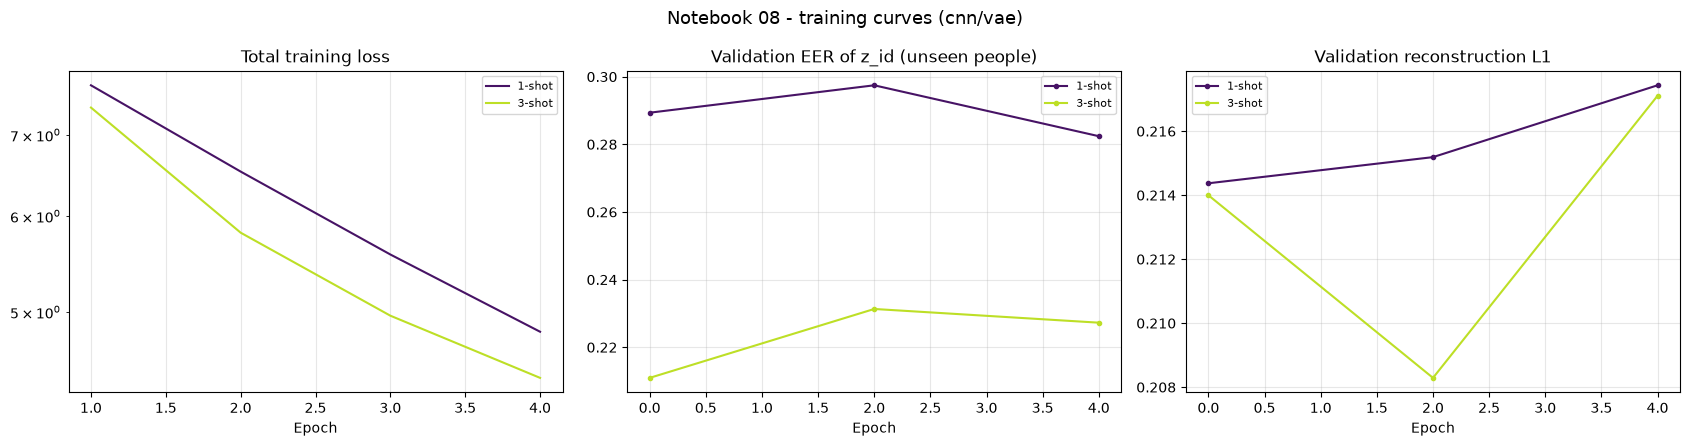

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_training_curves.png


In [20]:
# ============================================================
# 17a. Training curves
# ============================================================

primary_encoder, primary_mode, primary_seed = ENCODERS[0], LATENT_MODES[0], SEEDS[0]
primary_history = history[(history["encoder"] == primary_encoder) & (history["mode"] == primary_mode)
                          & (history["seed"] == primary_seed)]
shots_present = sorted(primary_history["shot"].unique())
colors = dict(zip(shots_present, plt.cm.viridis(np.linspace(0.05, 0.9, max(len(shots_present), 1)))))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

for shot in shots_present:
    h = primary_history[primary_history["shot"] == shot].sort_values("epoch")
    train = h[h["epoch"] >= 1]
    validated = h.dropna(subset=["val_eer_id"])

    axes[0].plot(train["epoch"], train["loss"], color=colors[shot], label=f"{shot}-shot")
    axes[1].plot(validated["epoch"], validated["val_eer_id"], marker="o", markersize=3, color=colors[shot], label=f"{shot}-shot")
    axes[2].plot(validated["epoch"], validated["val_recon"], marker="o", markersize=3, color=colors[shot], label=f"{shot}-shot")

axes[0].set_title("Total training loss")
axes[0].set_yscale("log")
axes[1].set_title("Validation EER of z_id (unseen people)")
axes[2].set_title("Validation reconstruction L1")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle(f"Notebook 08 - training curves ({primary_encoder}/{primary_mode})", fontsize=13)
plt.tight_layout()
curves_path = RESULTS_DIR / "latent_training_curves.png"
plt.savefig(curves_path, dpi=200, bbox_inches="tight")
plt.show()
print("Saved:", curves_path)

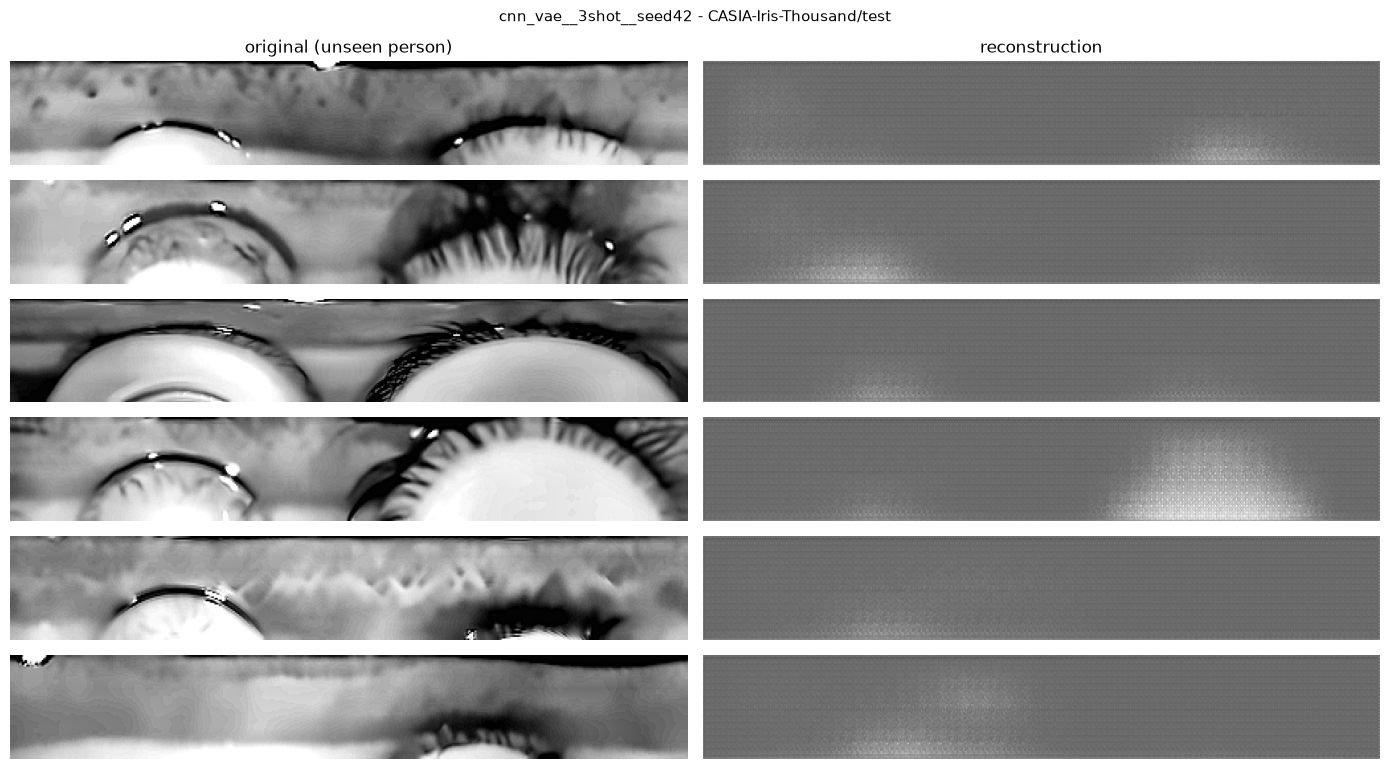

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_reconstructions_cnn_vae__3shot__seed42.png


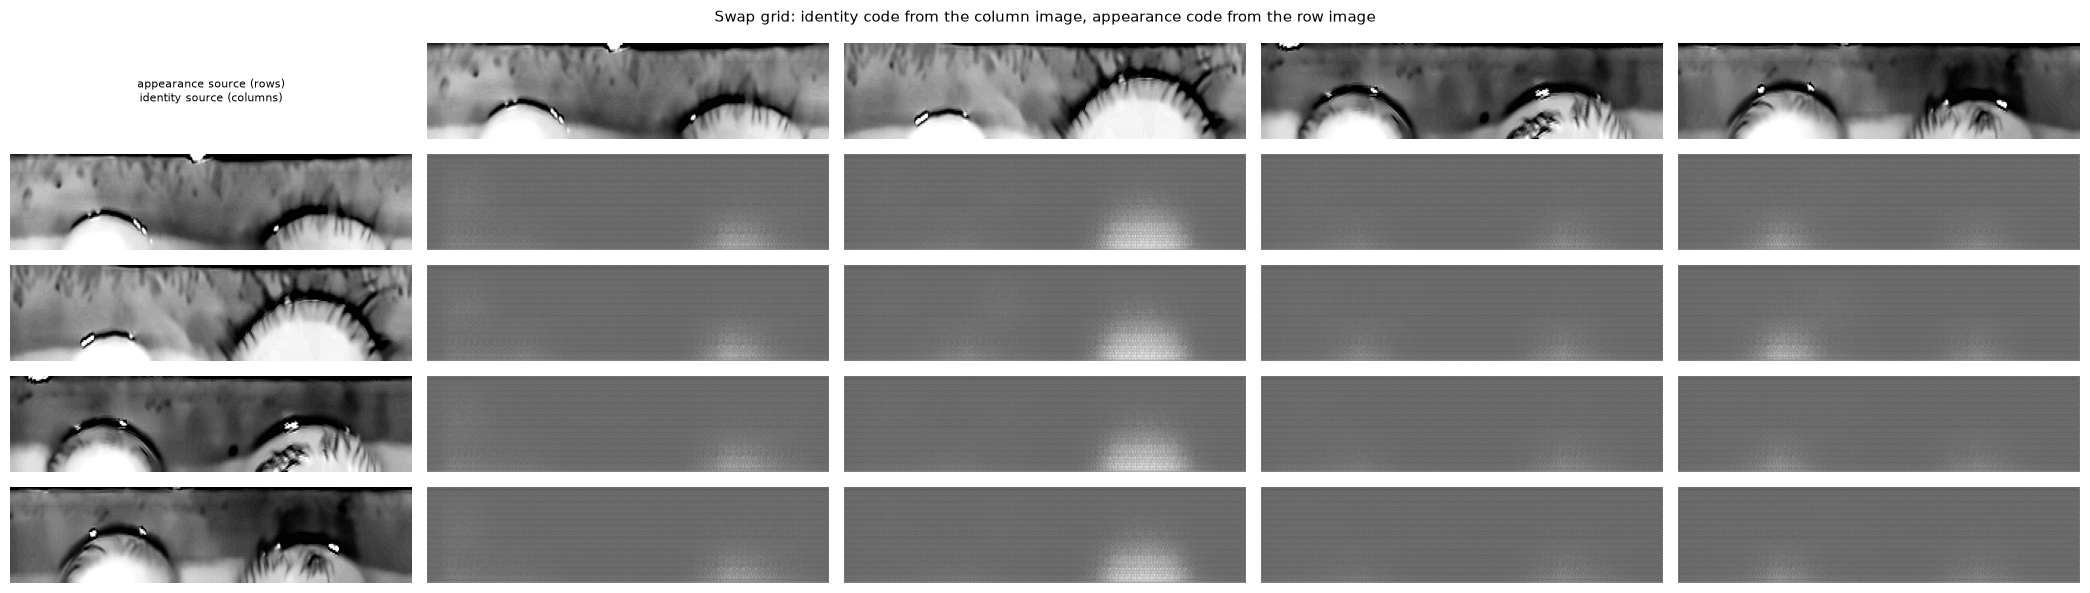

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_swap_grid_cnn_vae__3shot__seed42.png


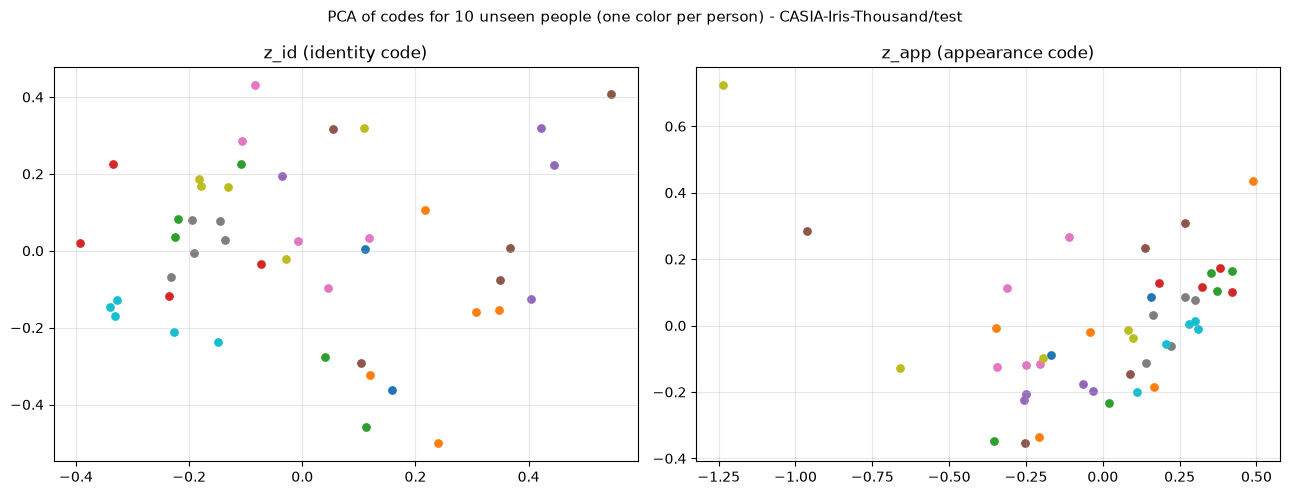

Saved: E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest\latent_projection_cnn_vae__3shot__seed42.png


In [21]:
# ============================================================
# 17b. Reconstructions, swap grid, and latent projection
# ============================================================

def pca_2d(z):
    '''2-D PCA with PyTorch (no NumPy linear algebra).'''
    centered = z - z.mean(dim=0, keepdim=True)
    _, _, vh = torch.linalg.svd(centered, full_matrices=False)
    return torch.matmul(centered, vh[:2].t()).numpy()


def show_latent_figures(run_id, shot, n_show=6):
    checkpoint_path = CHECKPOINT_DIR / f"{run_id}.pt"
    if not checkpoint_path.exists():
        print("Checkpoint not found; skipping figures for", run_id)
        return

    model, _ = load_latent_model(checkpoint_path)
    pools = get_eval_pool_defs(shot)
    pool_name = next((n for n, p in pools.items() if p["spec"]["kind"] == "within_dataset_test"), next(iter(pools)))
    query_df = pools[pool_name]["query_df"].reset_index(drop=True)

    def to_float(df):
        return load_image_tensor(df).to(DEVICE).float().div_(255.0).unsqueeze(1)

    with torch.no_grad():
        # ---- reconstructions ----
        picks = query_df.iloc[np.linspace(0, len(query_df) - 1, n_show).astype(int)]
        x = to_float(picks)
        mu_id, _, mu_app, _ = model.encode(x)
        reconstruction = model.decode(mu_id, mu_app)

        fig, axes = plt.subplots(n_show, 2, figsize=(14, 1.3 * n_show))
        for i in range(n_show):
            axes[i, 0].imshow(x[i, 0].cpu(), cmap="gray", aspect="auto", vmin=0, vmax=1)
            axes[i, 1].imshow(reconstruction[i, 0].cpu(), cmap="gray", aspect="auto", vmin=0, vmax=1)
            axes[i, 0].axis("off"); axes[i, 1].axis("off")
        axes[0, 0].set_title("original (unseen person)"); axes[0, 1].set_title("reconstruction")
        plt.suptitle(f"{run_id} - {pool_name}", fontsize=11)
        plt.tight_layout()
        path = RESULTS_DIR / f"latent_reconstructions_{run_id}.png"
        plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show(); print("Saved:", path)

        # ---- swap grid: columns = identity source, rows = appearance source ----
        first_per_class = query_df.drop_duplicates("class_id").head(4)
        if len(first_per_class) >= 2:
            xs = to_float(first_per_class)
            id_codes, _, app_codes, _ = model.encode(xs)
            k = len(first_per_class)

            fig, axes = plt.subplots(k + 1, k + 1, figsize=(4.2 * (k + 1), 1.2 * (k + 1)))
            for r in range(k + 1):
                for c in range(k + 1):
                    axes[r, c].axis("off")
            axes[0, 0].text(0.5, 0.5, "appearance source (rows)\nidentity source (columns)", ha="center", va="center", fontsize=8)
            for j in range(k):
                axes[0, j + 1].imshow(xs[j, 0].cpu(), cmap="gray", aspect="auto", vmin=0, vmax=1)
                axes[j + 1, 0].imshow(xs[j, 0].cpu(), cmap="gray", aspect="auto", vmin=0, vmax=1)
            for i in range(k):            # appearance source
                for j in range(k):        # identity source
                    swapped = model.decode(id_codes[j:j + 1], app_codes[i:i + 1])
                    axes[i + 1, j + 1].imshow(swapped[0, 0].cpu(), cmap="gray", aspect="auto", vmin=0, vmax=1)
            plt.suptitle("Swap grid: identity code from the column image, appearance code from the row image", fontsize=11)
            plt.tight_layout()
            path = RESULTS_DIR / f"latent_swap_grid_{run_id}.png"
            plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show(); print("Saved:", path)

        # ---- 2-D projection of z_id and z_app for a few people ----
        chosen = query_df["class_id"].drop_duplicates().head(10)
        subset = pools[pool_name]["query_df"][pools[pool_name]["query_df"]["class_id"].isin(chosen)]
        encoded = encode_images(model, load_image_tensor(subset), reconstruct=False)
        names = subset["class_id"].to_numpy()

        fig, axes = plt.subplots(1, 2, figsize=(13, 5))
        for ax, key, title in [(axes[0], "z_id", "z_id (identity code)"), (axes[1], "z_app", "z_app (appearance code)")]:
            points = pca_2d(F.normalize(encoded[key], dim=1))
            for color_index, class_name in enumerate(chosen):
                mask = names == class_name
                ax.scatter(points[mask, 0], points[mask, 1], s=28, color=plt.cm.tab10(color_index % 10))
            ax.set_title(title); ax.grid(alpha=0.3)
        plt.suptitle(f"PCA of codes for {len(chosen)} unseen people (one color per person) - {pool_name}", fontsize=11)
        plt.tight_layout()
        path = RESULTS_DIR / f"latent_projection_{run_id}.png"
        plt.savefig(path, dpi=150, bbox_inches="tight"); plt.show(); print("Saved:", path)


if SAVE_CHECKPOINTS:
    largest_shot = max(shots_present)
    show_latent_figures(make_run_id(primary_encoder, primary_mode, largest_shot, primary_seed), largest_shot)
else:
    print("SAVE_CHECKPOINTS is False; skipping the model-based figures.")

## 18. Sanity checks

A broken latent model would silently damage the generator and everything after it, so the results are checked before they are handed on:

- every planned run finished, passed the leakage assertions, and exported its files with the right sizes;
- the identity embeddings are unit length;
- training reduced the loss and the validation reconstruction error;
- `z_id` identifies unseen people clearly above chance, **more** than `z_app` does;
- the swap test and the invariance gap show that the codes are separated;
- a reloaded checkpoint reproduces the reported validation numbers.

Failures of the first group stop the notebook; the second group are warnings, because their thresholds describe expected behavior rather than guaranteed behavior.

In [22]:
# ============================================================
# 18. Sanity checks
# ============================================================

checks = []


def add_check(name, passed, details="", critical=True):
    checks.append({"check": name, "passed": bool(passed), "critical": critical, "details": details})
    status = "PASS" if passed else ("FAIL" if critical else "WARN")
    print(f"[{status}] {name}" + (f"  ({details})" if details else ""))


expected_ids = {make_run_id(e, m, s, sd) for (e, m, s, sd) in plan}
missing_runs = expected_ids - set(runs_table["run_id"])
add_check("all planned runs are present", not missing_runs, f"{len(missing_runs)} missing")
add_check("every run passed the train/evaluation leakage assertions", bool(runs_table["leakage_checks_passed"].all()))

if EXPORT_LATENTS:
    bad_exports = []
    for _, run in runs_table.iterrows():
        shot_rows = int((long_manifest["shot"] == run["shot"]).sum())
        try:
            latent = np.load(run["latent_file"], allow_pickle=False)
            embeddings = np.load(run["identity_embedding_file"], allow_pickle=False)
            ok = (latent["z_id"].shape == (shot_rows, ID_DIM) and latent["z_app"].shape == (shot_rows, APP_DIM)
                  and len(latent["image_id"]) == shot_rows and np.isfinite(latent["z_id"]).all()
                  and embeddings["embedding"].shape[1] == ID_DIM
                  and np.allclose(np.linalg.norm(embeddings["embedding"], axis=1), 1.0, atol=1e-4))
        except Exception as error:
            ok = False
        if not ok:
            bad_exports.append(run["run_id"])
    add_check("exported latent vectors and identity embeddings have the right shapes (embeddings unit length)",
              not bad_exports, f"{len(bad_exports)} run(s) with problems")

not_decreasing = runs_table[runs_table["final_loss"] >= runs_table["initial_loss"]]
add_check("training loss decreased in every run", len(not_decreasing) == 0, f"{len(not_decreasing)} run(s) did not improve")

final_recon = results[results["kind"] == "selection"].set_index("run_id")["recon_l1"]
initial_recon = runs_table.set_index("run_id")["initial_val_recon"]
improved = (final_recon.reindex(initial_recon.index) < initial_recon).fillna(False)
add_check("validation reconstruction error improved over the untrained model", bool(improved.all()),
          f"{int((~improved).sum())} run(s) did not improve", critical=False)

test_rows = results[results["kind"] == "within_dataset_test"]
if len(test_rows):
    weak = test_rows[test_rows["id_rank1_acc"] <= 2 * test_rows["chance_rank1"]]
    add_check("z_id identifies unseen test people at more than twice chance", len(weak) == 0,
              f"{len(weak)} of {len(test_rows)} results are near chance", critical=False)

    leaky = test_rows[test_rows["app_rank1_acc"] >= test_rows["id_rank1_acc"]]
    add_check("z_app identifies people less well than z_id (no identity leakage into z_app)", len(leaky) == 0,
              f"{len(leaky)} of {len(test_rows)} results have z_app >= z_id", critical=False)

    weak_swap = test_rows[test_rows["swap_acc_id"] <= 0.5]
    add_check("swap test: the swapped image keeps the identity of the identity source", len(weak_swap) == 0,
              f"{len(weak_swap)} of {len(test_rows)} results at or below 0.5", critical=False)

    no_gap = test_rows[test_rows["inv_gap"] <= 0]
    add_check("z_id is invariant to appearance changes (positive invariance gap)", len(no_gap) == 0,
              f"{len(no_gap)} of {len(test_rows)} results without a gap", critical=False)

# a reloaded checkpoint must reproduce the reported validation numbers
if SAVE_CHECKPOINTS:
    run = runs_table.iloc[0]
    checkpoint_path = CHECKPOINT_DIR / f"{run['run_id']}.pt"
    reported = results[(results["run_id"] == run["run_id"]) & (results["kind"] == "selection")]
    if checkpoint_path.exists() and len(reported):
        reloaded, _ = load_latent_model(checkpoint_path)
        pool_name = reported["eval_set"].iloc[0]
        tensors = materialize_pool(get_eval_pool_defs(int(run["shot"]))[pool_name])
        again = quick_validate(reloaded, tensors, pool_name, int(run["shot"]))
        difference = abs(again["eer_id"] - reported["id_eer"].iloc[0])
        add_check("a reloaded checkpoint reproduces the reported validation EER", difference < 1e-3,
                  f"difference {difference:.2e}", critical=False)

sanity_report = pd.DataFrame(checks)
sanity_report.to_csv(RESULTS_DIR / "latent_sanity_checks.csv", index=False)
print("\nSaved:", RESULTS_DIR / "latent_sanity_checks.csv")

critical_failures = sanity_report[(~sanity_report["passed"]) & sanity_report["critical"]]
failed_names = list(critical_failures["check"])
assert len(critical_failures) == 0, f"Critical latent-space checks failed: {failed_names}"
print("\nLatent-space sanity checks completed with no critical failures.")

[PASS] all planned runs are present  (0 missing)
[PASS] every run passed the train/evaluation leakage assertions
[PASS] exported latent vectors and identity embeddings have the right shapes (embeddings unit length)  (0 run(s) with problems)
[PASS] training loss decreased in every run  (0 run(s) did not improve)
[WARN] validation reconstruction error improved over the untrained model  (2 run(s) did not improve)
[PASS] z_id identifies unseen test people at more than twice chance  (0 of 2 results are near chance)
[PASS] z_app identifies people less well than z_id (no identity leakage into z_app)  (0 of 2 results have z_app >= z_id)
[WARN] swap test: the swapped image keeps the identity of the identity source  (1 of 2 results at or below 0.5)
[PASS] z_id is invariant to appearance changes (positive invariance gap)  (0 of 2 results without a gap)
[PASS] a reloaded checkpoint reproduces the reported validation EER  (difference 0.00e+00)

Saved: E:\Research\LargeScale_Synthetic_Iris_Generatio

## 19. Final outputs

At the end of Notebook 08, the project should contain:

```text
results/identity_latent_space/
├── latents/<run_id>.npz              latent vectors (z_id, z_app) of every image of that shot
├── identity_embeddings/<run_id>.npz  one identity embedding per class
├── runs/                             one JSON record per training run
├── latent_results.csv                every metric, every run, every evaluation set
├── latent_summary.csv                averaged over seeds
├── latent_runs.csv, latent_training_history.csv, latent_manifest.csv, latent_roc.csv
├── latent_sanity_checks.csv
└── latent_*.png                      curves, reconstructions, swap grid, projection

checkpoints/identity_latent_space/<run_id>.pt     best-validation weights per run
```

`<run_id>` looks like `cnn_vae__3shot__seed42`.

In [23]:
# ============================================================
# 19. Final output listing
# ============================================================

print("Notebook 08 output directory:")
print(RESULTS_DIR)

print("\nTop-level generated files:")
for path in sorted(RESULTS_DIR.iterdir()):
    if path.is_file():
        print(f"- {path.name}")

print(f"\nLatent files: {len(list(LATENT_DIR.glob('*.npz')))} | identity-embedding files: "
      f"{len(list(IDENTITY_DIR.glob('*.npz')))} | run records: {len(list(RUNS_DIR.glob('*.json')))} | "
      f"checkpoints: {len(list(CHECKPOINT_DIR.glob('*.pt')))}")
print("\nNotebook 08 completed.")

Notebook 08 output directory:
E:\Research\LargeScale_Synthetic_Iris_Generation\results\identity_latent_space_quicktest

Top-level generated files:
- latent_manifest.csv
- latent_projection_cnn_vae__3shot__seed42.png
- latent_reconstructions_cnn_vae__3shot__seed42.png
- latent_results.csv
- latent_roc.csv
- latent_runs.csv
- latent_sanity_checks.csv
- latent_summary.csv
- latent_swap_grid_cnn_vae__3shot__seed42.png
- latent_training_curves.png
- latent_training_history.csv

Latent files: 2 | identity-embedding files: 2 | run records: 2 | checkpoints: 2

Notebook 08 completed.


## 20. What this notebook hands to the rest of the project

```text
Notebook 06 + 07            Notebook 08                         Notebooks 09 - 12
Few-shot dataset,  --->     Latent model:                --->   Generator conditioned on z_id,
baseline numbers            z_id (identity), z_app (appearance)  images with z_id fixed and z_app varied,
                            latent vectors, identity embeddings  identity verification, diversity
```

### Loading the outputs

```python
data = np.load(RESULTS_DIR / "latents" / "cnn_vae__3shot__seed42.npz", allow_pickle=False)
data["z_id"], data["z_app"], data["image_id"], data["class_id"], data["split"], data["role"]

ident = np.load(RESULTS_DIR / "identity_embeddings" / "cnn_vae__3shot__seed42.npz", allow_pickle=False)
ident["class_id"], ident["split"], ident["embedding"]        # one unit-length row per class
```

### How each later notebook uses it

| Notebook | Use |
|---|---|
| **09 Generator** | Condition on `z_id` (or the class identity embedding) of the **training** classes. Learn the distribution of `z_app` from the training images' `z_app`. |
| **10 Synthetic generation** | For each training identity keep its identity embedding fixed and draw different appearance codes (for example the `z_app` of other training images). |
| **11 Identity verification** | Compare each synthetic image with its identity using a recognizer (Notebook 07 / 13 embedding) and, as a second opinion, the encoder of this notebook. |
| **12 Diversity** | The spread of `z_app` among the synthetic images of one identity is a direct measure of intra-class variation. |

### Rules that keep the no-leakage guarantee intact

1. **Only `train / support` images may be used to fit the generator** and any other generative model. The `val` and `test` identities (and the IITD cross-dataset images) have latent vectors here **only for evaluation**; never train on them or condition synthetic generation on them.
2. **Synthetic images inherit the split of their identity.** They are used for training only; validation and test stay real.
3. Use the **same shot** for the latent model and the generator: the `3shot` latent model has only seen the 3 support images per training identity.
4. Report the configuration fingerprint (`CONFIG_HASH`) and the seed with every number.

### Reading the diagnostics

| What you see | Likely cause | What to try |
|---|---|---|
| `z_id` EER near 0.5 | Identity is not being learned | Raise `W_ID` or `W_TRIPLET`, check the training loss |
| `z_app` Rank-1 close to `z_id` Rank-1 | Identity leaks into `z_app` | Raise `W_KL_APP`, lower `APP_DIM`, raise `W_SWAP` |
| Swap accuracy near 0.5, blurry swaps | The codes are not separated | Raise `W_SWAP`, make the transform stronger |
| Sharp reconstructions but weak `z_id` | Reconstruction dominates | Lower `W_RECON` / `W_SWAP` or raise `W_ID` |
| Blurry reconstructions, KL near 0 | Posterior collapse | Lower `W_KL_ID` / `W_KL_APP`, lengthen `KL_WARMUP_EPOCHS` |